# Infinite cardinality choice

<a href="https://colab.research.google.com/github/sixhobbits/colab-demo/blob/main/cookbooks/infinite_cardinality_choice/infinite_cardinality_choice.ipynb" target="_blank"><img src="https://img.shields.io/badge/Open%20in%20Colab-F9AB00?style=for-the-badge&logo=googlecolab&logoColor=white" alt="Open in Colab" height="28"></a> <a href="https://github.com/sixhobbits/colab-demo/blob/main/cookbooks/infinite_cardinality_choice/infinite_cardinality_choice.ipynb" target="_blank"><img src="https://img.shields.io/badge/View%20on%20GitHub-24292F?style=for-the-badge&logo=github&logoColor=white" alt="View on GitHub" height="28"></a>

> **No API key needed.** The code downloads this cookbook's saved answers, so
> *Run all* replays every TypeSafe call from them. It needs no TypeSafe account
> and costs nothing. To call the API yourself, set `TYPESAFE_API_KEY` and
> `DOWNLOAD_CACHE = False`.

From [the docs page](https://console.typesafe.ai/docs/cookbooks/infinite_cardinality_choice).

Someone remembers a film but not its title, and describes it instead: "a man and a boy
running from these sharp metal eyeball things with blades on the side". They saw it in the
90s. The film is one of 5,000 in a catalog, and its plot summary tells the same story in
different words.

One `Choice` question can pick the film from a list, but it takes at most 255 options, and
only about forty when each option is a long plot summary. So the search runs in three
steps, and each step reads more about fewer films:

1. Ask one `Noul` question per film, "is this the film they mean?", with the first hundred
   words of its plot. The questions go out in chunks, all at once, so the wait stays about
   the same as the catalog grows, as long as your rate limit allows that many calls at a
   time.
2. Ask again about the eighty films with the highest probabilities, this time with six
   hundred words of plot.
3. Put the top twenty in one `Choice` question. Its top probability tells you whether to
   show one film or a short list.

The 100 requests here come from a forum where people ask for help naming a film, each
answered by someone who recognised it. When embedding search picks the twenty films for
step 3 instead, the right film comes first for 33% of them. With all three steps, it
comes first for 78%. Each of the 48 times the Choice question gave its top film 0.8 or
more, that film was right.

The result is a `find()` function that takes a request and returns the films ranked by
probability, in three rounds of parallel calls.

<img src="https://raw.githubusercontent.com/sixhobbits/colab-demo/main/cookbooks/infinite_cardinality_choice/infinite_cardinality_choice-diagram-584d88e272.png" alt="Diagram" width="1176">

## Setup

```bash
pip install openai ipython matplotlib 'cooksafe>=0.3.0,<0.4.0'
```

then set `TYPESAFE_API_KEY`, and `OPENAI_API_KEY` for the embedding search the results are
measured against. The code downloads the published answers into
`infinite_cardinality_choice_cache.json`, so the run makes no requests; to run live, set
`DOWNLOAD_CACHE = False` and delete that file.

Numbers below came from `jev-1.14.0`, run in November 2026.

In [ ]:
%pip install -q 'openai' 'typesafe-sdk>=0.7.0' 'ipython' 'matplotlib' 'cooksafe>=0.3.0,<0.4.0'

In [ ]:
import json
import os
import urllib.request
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
from time import perf_counter

import matplotlib
import matplotlib.pyplot as plt
from cooksafe import JsonCache, make_playground_link
from IPython.display import Markdown, display
from typesafe_sdk import Choice, Noul, RetryPolicy, TypeSafeClient

matplotlib.use("Agg")  # headless render

TYPESAFE_MODEL = "jev-1.14.0"  # the page's model; "jev-latest" runs the newest, live
CHOICE_LIMIT = 255  # enforced by the API; 256 options is rejected outright
CHUNK = 300  # films per filter call: ~150 tokens each keeps a call well under 64k
LONG_CHUNK = 40  # films per re-read call: ~700 tokens each, ~28k a call
FIRST_CUT = 80  # films read again with their long plot
CANDIDATES = 20  # films the Choice question sees
WORKERS = 4  # searches run side by side, each sending all its chunks at once

client = TypeSafeClient(
    api_key=os.environ.get("TYPESAFE_API_KEY", "cache-only"),  # keyless kernels replay the cache
    base_url=os.environ.get("TYPESAFE_ENDPOINT"),
    timeout=300.0,  # 300 questions is a big request
    # a request this size occasionally draws an overload response, so retries are not optional
    retry=RetryPolicy(max_retries=5, backoff_initial=1.0, backoff_max=30.0),
)


EXAMPLES = (
    "https://raw.githubusercontent.com/typesafe-ai/typesafe-public-examples/main/"
    "cookbooks/infinite_cardinality_choice"
)


def download(name: str) -> Path:
    """Fetch one of this cookbook's files from typesafe-public-examples unless it is on disk."""
    path = Path(name)
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f"{EXAMPLES}/{name}", path)
    return path


CACHE = Path("infinite_cardinality_choice_cache.json")
# True fills CACHE with the published answers, so the run makes no requests. To run
# live, set it to False and delete CACHE; a CACHE already on disk is never overwritten.
DOWNLOAD_CACHE = True
if DOWNLOAD_CACHE:
    download(CACHE.name)
json_cache = JsonCache(CACHE)

## Load the catalog and the requests

The catalog is `films.jsonl`: each film's title, year, and two versions of the plot section
of its Wikipedia article, fetched 2026-11-07. The short one, `plot`, is the first hundred
or so words, and step 1 reads it. The long one, `long_plot`, is the first six hundred or
so, and steps 2 and 3 read it. The catalog holds the film behind every request. The other
films, the ones a search has to rule out, are those whose Wikipedia articles exist in the
most languages.

The 100 requests in `requests.jsonl` come from Microsoft's tip-of-the-tongue dataset,
collected from the forum iRememberThisMovie.com, and each comes with the film that answered
it. They are a random sample of the 709 whose film has a plot section on Wikipedia.

In [ ]:
FILMS = {f["id"]: f for f in map(json.loads, download("films.jsonl").read_text().splitlines())}
REQUESTS = [json.loads(line) for line in download("requests.jsonl").read_text().splitlines()]


def label(film_id: str) -> str:
    film = FILMS[film_id]
    return f"{film['title']} ({film['year']})" if film["year"] else film["title"]


example = next(r for r in REQUESTS if r["id"] == "388")
print(f"{len(FILMS):,} films, {len(REQUESTS)} requests\n")
print(f"request {example['id']}:\n  {example['text']}\n")
print(f"the film: {label(example['film'])}\n  {FILMS[example['film']]['plot']}")

5,000 films, 100 requests

request 388:
  Mother and her two kids (a boy and a girl) are tormented by ghosts that turn out to be time travelers. I think the dad has recently died and the boy has some behavior issues and he is getting kicked out of or about to be kicked out of school. The mom has a boyfriend. There is a guy trying to get the mom to sell their house. Later, the kids get sick when they try to leave the house.

the film: The Diabolical (2015)
  Madison, a single mother, lives with her two children, Jacob and Hayleigh, in a suburban home. Madison's financial difficulties prompt her to consider declaring bankruptcy. Jacob was involved in a fight six months prior and now sees a counselor to evaluate his state of mind. Madison is dating her son's science tutor, Nikolai. The family experiences paranormal occurrences that manifest as a bloody and bound apparition and a bald man. Although Madison hires parapsychologists and psychics to investigate the haunting, none can help her.

## Step 1: filter with one Noul question per film

Each Noul question names one film as the answer and includes its plot, so Jev compares the
request with the plot instead of recalling the film from its title.

A call holds at most 64k tokens, so split the catalog into chunks that fit. No chunk
depends on another, so send them all at once.

In [ ]:
def proposition(film_id: str, plot: str = "plot") -> str:
    return (
        f"The film this person is trying to remember is {label(film_id)}. "
        f"Its plot: {FILMS[film_id][plot]}"
    )


def as_json(questions: dict) -> str:
    """The questions as API JSON, so the cache key changes when their wording does."""
    return json.dumps(
        {key: q.model_dump(mode="json", exclude_none=True) for key, q in questions.items()}
    )


IDS = sorted(FILMS)
CHUNKS = [
    as_json({i: Noul(instructions=proposition(i)) for i in IDS[start : start + CHUNK]})
    for start in range(0, len(IDS), CHUNK)
]


@json_cache
def filter_chunk(text: str, questions_json: str, model: str) -> dict:
    started = perf_counter()
    response = client.system_one(
        state=text, questions=json.loads(questions_json), model=model
    )
    return {
        "p": {key: answer.noul for key, answer in response.answers.items()},
        "seconds": round(perf_counter() - started, 2),
    }


def filter_films(text: str) -> dict:
    """Every chunk at once; one probability per film."""
    with ThreadPoolExecutor(max_workers=len(CHUNKS)) as pool:
        parts = list(
            pool.map(lambda chunk: filter_chunk(text, chunk, model=TYPESAFE_MODEL), CHUNKS)
        )
    return {key: p for part in parts for key, p in part["p"].items()}


def by_probability(request: dict) -> list[str]:
    p = filter_films(request["text"])
    return sorted(p, key=lambda key: (-p[key], key))


filtered = filter_films(example["text"])
seconds = [
    filter_chunk(example["text"], chunk, model=TYPESAFE_MODEL)["seconds"] for chunk in CHUNKS
]
print(f"{len(filtered):,} answers from {len(CHUNKS)} calls sent together; the slowest "
      f"took {max(seconds)}s\n")
print("the filter's own top five:")
for key in by_probability(example)[:5]:
    mark = "  <- the film" if key == example["film"] else ""
    print(f"  {filtered[key]:.2f}  {label(key)}{mark}")
print(f"\nthe film is at position {by_probability(example).index(example['film']) + 1}")
held = sum(1 for r in REQUESTS if r["film"] in by_probability(r)[:FIRST_CUT])
print(f"the top {FIRST_CUT} hold the right film for {held}/{len(REQUESTS)} requests")

5,000 answers from 17 calls sent together; the slowest took 0.4s

the filter's own top five:
  0.64  Ghostbusters: Afterlife (2021)
  0.37  The Curse of La Llorona (2019)
  0.33  Thirteen Ghosts (2001)
  0.31  Mama (2013)
  0.31  Wicked Little Things (2006)

the film is at position 6
the top 80 hold the right film for 93/100 requests


## Step 2: read the top eighty again, with the long plot

For this request, the filter ranks *Ghostbusters: Afterlife* first at 0.64. It matches on
a mother, two kids, a haunted house and money trouble. *The Diabolical* is sixth. The
request's most specific detail is that the ghosts "turn out to be time travelers". In the
plot of *The Diabolical*, that twist comes after the first hundred words, so the filter
never sees it. People remember scenes from anywhere in a film.

So ask again about the filter's top eighty, with six hundred words of each plot. Longer
questions mean fewer films per chunk, and the chunks still go out together. The filter's
top eighty hold the right film for 93 of the 100 requests, and this step has to move it
into the top twenty.

In [ ]:
def reread(request: dict) -> dict:
    """The filter's top films, asked again with the long plot; one probability per film."""
    first = by_probability(request)[:FIRST_CUT]
    chunks = [
        as_json({i: Noul(instructions=proposition(i, "long_plot"))
                 for i in first[start : start + LONG_CHUNK]})
        for start in range(0, FIRST_CUT, LONG_CHUNK)
    ]
    with ThreadPoolExecutor(max_workers=len(chunks)) as pool:
        parts = list(
            pool.map(
                lambda chunk: filter_chunk(request["text"], chunk, model=TYPESAFE_MODEL), chunks
            )
        )
    return {key: p for part in parts for key, p in part["p"].items()}


def candidates(request: dict) -> tuple[str, ...]:
    p = reread(request)
    return tuple(sorted(p, key=lambda key: (-p[key], key))[:CANDIDATES])


reread_p = reread(example)
print("the long plots' top five:")
for key in candidates(example)[:5]:
    mark = "  <- the film" if key == example["film"] else ""
    print(f"  {reread_p[key]:.2f}  {label(key)}{mark}")
held = sum(1 for r in REQUESTS if r["film"] in candidates(r))
print(f"\nthe top {CANDIDATES} hold the right film for {held}/{len(REQUESTS)} requests")

the long plots' top five:
  0.60  The Diabolical (2015)  <- the film
  0.40  Ghostbusters: Afterlife (2021)
  0.30  The Others (2001)
  0.26  Thirteen Ghosts (2001)
  0.17  Knowing (2009)

the top 20 hold the right film for 88/100 requests


The long plot includes the twist: the apparition is the son, come back from the future.
*The Diabolical* moves to first at 0.60. Across all requests, the top twenty now hold the
right film for 88, against 82 for the filter's top twenty alone.

## Step 3: decide with one Choice question

Put the top twenty in one `Choice` question, with their long plots as the options. Each
Noul question judges its film alone, so two films that both fit the request can both get
0.4 or more, here 0.60 and 0.40, and the top five alone add up to more than 1. A Choice
question weighs the twenty films against each other, so its top probability says how far
ahead of the rest the top film is.

In [ ]:
DECISION = "Which film is this person trying to remember?"


def decision_question(options: tuple[str, ...]) -> dict:
    return {
        "film": Choice(
            instructions=DECISION,
            criteria={key: f"{label(key)}: {FILMS[key]['long_plot']}" for key in options},
        )
    }


@json_cache
def rank(text: str, questions_json: str, model: str) -> dict:
    response = client.system_one(
        state=text, questions=json.loads(questions_json), model=model
    )
    answer = response.answers["film"]
    return {"film": answer.choice, "confidence": answer.confidence,
            "probabilities": dict(answer.probabilities)}


def find(request: dict, options: tuple[str, ...] | None = None) -> dict:
    """Rank a shortlist with one Choice; by default, the top twenty on the long plots."""
    options = candidates(request) if options is None else options
    ranked = rank(request["text"], as_json(decision_question(options)), model=TYPESAFE_MODEL)
    p = ranked["probabilities"]
    return {"film": ranked["film"], "order": sorted(p, key=lambda key: (-p[key], key)),
            "confidence": ranked["confidence"], "probabilities": p}


result = find(example)
print("the Choice's own top five, out of the twenty it was given:")
for key in result["order"][:5]:
    mark = "  <- the film" if key == example["film"] else ""
    print(f"  {result['probabilities'][key]:.2f}  {label(key)}{mark}")

the Choice's own top five, out of the twenty it was given:
  1.00  The Diabolical (2015)  <- the film
  0.00  Beetlejuice Beetlejuice (2024)
  0.00  Dark Water (2002)
  0.00  Ghostbusters: Afterlife (2021)
  0.00  Ghostbusters: Frozen Empire (2024)


The Choice question puts 1.00 on *The Diabolical*.

To search your own catalog, give each item a short and a long description and rewrite
`FILMS`, `proposition()` and `decision_question()`. Nothing else mentions films.

## Measure what each step is worth

The `embeddings` column uses embedding search, the standard first try for matching text
that says the same thing in other words. It embeds each film's short plot and the request
with OpenAI's `text-embedding-3-small`, and the twenty closest films go to the same Choice
question. The `no re-read` column sends the filter's top twenty straight to
the Choice question, skipping step 2.

In [ ]:
import numpy as np  # noqa: E402
from openai import OpenAI  # noqa: E402

EMBED_MODEL = "text-embedding-3-small"
embedder = OpenAI(api_key=os.environ.get("OPENAI_API_KEY", "cache-only"))


def embed(texts: list[str], embed_model: str) -> np.ndarray:
    """Unit-length embeddings, 256 texts per call."""
    vectors = []
    for start in range(0, len(texts), 256):
        response = embedder.embeddings.create(model=embed_model, input=texts[start : start + 256])
        vectors += [item.embedding for item in response.data]
    vectors = np.array(vectors)
    return vectors / np.linalg.norm(vectors, axis=1, keepdims=True)


catalog_vectors = None  # the catalog is embedded only when a shortlist isn't cached yet


@json_cache
def embedding_shortlist(text: str, embed_model: str) -> list[str]:
    """The twenty films whose short plots sit closest to the request."""
    global catalog_vectors
    if catalog_vectors is None:
        catalog_vectors = embed([f"{label(i)}: {FILMS[i]['plot']}" for i in IDS], embed_model)
    similarity = catalog_vectors @ embed([text], embed_model)[0]
    order = sorted(range(len(IDS)), key=lambda n: (-similarity[n], IDS[n]))
    return [IDS[n] for n in order[:CANDIDATES]]


shortlists = {
    "embeddings": {
        r["id"]: tuple(embedding_shortlist(r["text"], embed_model=EMBED_MODEL)) for r in REQUESTS
    },
    "no re-read": {r["id"]: tuple(by_probability(r)[:CANDIDATES]) for r in REQUESTS},
    "all 3 steps": {r["id"]: candidates(r) for r in REQUESTS},
}

def position(film: str, order: list[str]) -> int:
    return order.index(film) + 1 if film in order else 10_000


found = {}
with ThreadPoolExecutor(max_workers=WORKERS) as pool:
    for name, lists in shortlists.items():
        found[name] = list(pool.map(lambda r: find(r, lists[r["id"]]), REQUESTS))
via_long = found["all 3 steps"]


def share(values) -> str:
    return f"{sum(values) / len(REQUESTS):.0%}"


print(f"  {'':<20}" + "".join(f"{name:>14}" for name in shortlists))
print(f"  {'reaches the Choice':<20}" + "".join(
    f"{share([r['film'] in lists[r['id']] for r in REQUESTS]):>14}"
    for lists in shortlists.values()))
for k in (1, 3):
    print(f"  {'film in the top ' + str(k):<20}" + "".join(
        f"{share([position(r['film'], f['order']) <= k for r, f in zip(REQUESTS, picks)]):>14}"
        for picks in found.values()))

                          embeddings    no re-read   all 3 steps
  reaches the Choice             35%           82%           88%
  film in the top 1              33%           73%           78%
  film in the top 3              34%           76%           82%


Embedding search holds the right film in its top twenty for 35% of requests, and the
Choice question puts it first for 33%: the Choice question can only rank the films it is
given. Reading short plots against the request gets the film into the top twenty for 82%
of requests, and re-reading the top eighty with long plots raises that to 88%. The right
film comes first for 73% without step 2 and 78% with it.

## Decide when to show one film

To decide between showing one film and showing a short list, you need a probability you
can set a threshold on. Both the re-read and the Choice question give their top film a
probability, and the table counts how often that film was right at each level.

In [ ]:
BANDS = ((0.0, 0.5, "under 0.5"), (0.5, 0.8, "0.5 to 0.8"), (0.8, 0.95, "0.8 to 0.95"),
         (0.95, 1.01, "0.95 and up"))
SOURCES = {
    "long-plot Nouls": [reread(r) for r in REQUESTS],
    "Choice question": [f["probabilities"] for f in via_long],
}


def top_answer(p: dict) -> tuple[str, float]:
    key = min(p, key=lambda k: (-p[k], k))
    return key, p[key]


bands = {}
for name, dists in SOURCES.items():
    bands[name] = []
    for low, high, _ in BANDS:
        hits_ = [key == r["film"] for r, p in zip(REQUESTS, dists)
                 for key, top in [top_answer(p)] if low <= top < high]
        bands[name].append((len(hits_), sum(hits_)))
print(f"  {'top answer':<14}" + "".join(f"{name:>24}" for name in SOURCES))
for i, (_, _, band) in enumerate(BANDS):
    cells = "".join(
        f"{f'{right}/{n} right':>24}" for n, right in (bands[name][i] for name in SOURCES)
    )
    print(f"  {band:<14}{cells}")

THRESHOLD = 0.8
sure = [(r, f) for r, f in zip(REQUESTS, via_long) if f["confidence"] >= THRESHOLD]
rest = [(r, f) for r, f in zip(REQUESTS, via_long) if f["confidence"] < THRESHOLD]
print(f"\nChoice at {THRESHOLD} or more: {len(sure)} requests, "
      f"right for {sum(f['film'] == r['film'] for r, f in sure)}")
print(f"below {THRESHOLD}: {len(rest)} requests, the film in the top 3 for "
      f"{sum(position(r['film'], f['order']) <= 3 for r, f in rest)}")

  top answer             long-plot Nouls         Choice question
  under 0.5                  30/49 right              9/30 right
  0.5 to 0.8                 33/40 right             21/22 right
  0.8 to 0.95                11/11 right             18/18 right
  0.95 and up                  0/0 right             30/30 right

Choice at 0.8 or more: 48 requests, right for 48
below 0.8: 52 requests, the film in the top 3 for 34


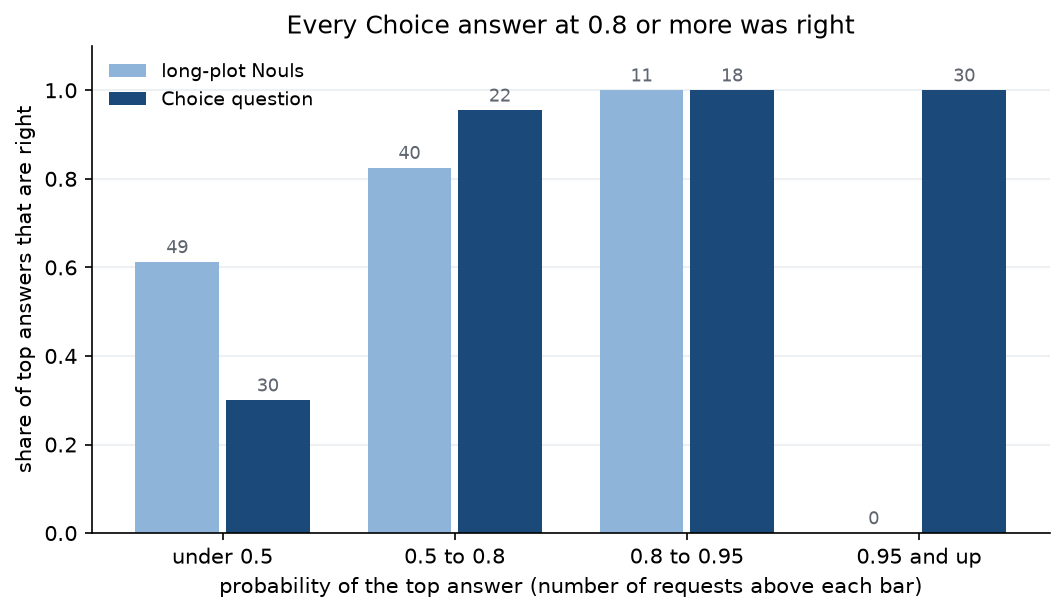

In [ ]:
BAR_PALETTES = {
    "light": {"surface": "#ffffff", "ink": "#000000", "note": "#5f6670", "grid": "#eef1f4",
              "bars": {"long-plot Nouls": "#8fb4d9", "Choice question": "#1b4a7a"}},
    "dark": {"surface": "#0d0a0f", "ink": "#fafafa", "note": "#9aa0a8", "grid": "#1f1b22",
             "bars": {"long-plot Nouls": "#3f6d9e", "Choice question": "#b4d2f2"}},
}


def draw_bands(p: dict) -> plt.Figure:
    ink = {key: p["ink"] for key in ("text.color", "axes.labelcolor", "axes.edgecolor",
                                     "xtick.color", "ytick.color")}
    with matplotlib.rc_context(ink):
        fig, ax = plt.subplots(figsize=(7.2, 4.2), facecolor=p["surface"])
        ax.set_facecolor(p["surface"])
        width = 0.36
        for j, name in enumerate(SOURCES):
            xs = [i + (j - 0.5) * (width + 0.03) for i in range(len(BANDS))]
            rates = [right / n if n else 0 for n, right in bands[name]]
            ax.bar(xs, rates, width=width, color=p["bars"][name], label=name, zorder=2)
            for x, rate, (n, _) in zip(xs, rates, bands[name]):
                ax.text(x, rate + 0.02, f"{n}", ha="center", fontsize=8.5, color=p["note"])
        ax.set_xticks(range(len(BANDS)))
        ax.set_xticklabels([band for _, _, band in BANDS])
        ax.set_xlabel("probability of the top answer (number of requests above each bar)")
        ax.set_ylabel("share of top answers that are right")
        ax.set_ylim(0, 1.1)
        ax.set_title(CHART_TITLE)
        ax.legend(frameon=False, loc="upper left", fontsize=9)
        ax.grid(axis="y", color=p["grid"], linewidth=1, zorder=0)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)
        fig.tight_layout()
        return fig


CHART_TITLE = "Every Choice answer at 0.8 or more was right"
# The docs build sets COOKSAFE_RENDER and also draws a dark copy.
for theme in ("light", "dark") if os.environ.get("COOKSAFE_RENDER") else ("light",):
    fig = draw_bands(BAR_PALETTES[theme])
    display(fig, metadata={"theme": theme})
    plt.close(fig)

The Choice question's top answer is at 0.8 or more for 48 requests, and right for all 48.
Under 0.5, it is right 9 times in 30. The re-read's probability can't sort requests into
sure and unsure: none of its answers reaches 0.95, only 11 reach 0.8, and its answers under
0.5 are still right 30 times in 49.

So decide with the Choice question's top probability. At 0.8 or more, show the one film.
Below 0.8, show the top three, which hold the right film for 34 of the other 52 requests.

## Open it in the playground

The playground can't comfortably show thousands of questions, so this link holds step 3
only: the request, and the Choice question over the twenty films the re-read kept.

In [ ]:
deeplink = make_playground_link(example["text"], decision_question(candidates(example)))
display(Markdown(f"🔗 [Open in the playground]({deeplink})"))

🔗 [Open in the playground](https://console.typesafe.ai/playground#share/N4IgJg9gxgrgtgUwHYBcAqCAeKQC4AEIAshCgBYIBO+AhkmPhdSgO4T4DWAlmAM74AKGvgBGEAJ616tfAHMulADYBKWpQT4UESolQIGIybLIReKfuRopNMSknwQY1raI0ouiTZRoA3BIqpeADp8AElNMi4kDgiNMBoGMhp+dShkFEVJMC59KQZyDTFJJP5eCE8RBCSfLm18Ll5eGAR+OkSNBrkEFHckWU4uKA5cx2sIADMHahoxJ012SoGhkbmJ-F4oEwhFELQKfDhyxmSZIvHKHPpdpg7WuRhJFEpxKP6XWW7Yg6OXXn9FWIKRiOP4hAAyVioABovtw+F1rLxBjEWBR7AVHs95vgAr43PsTDBQSAYSAAA6Ucpk8wYbB4QjAAA6IHGXEUcGZBCZIBQ4jJCE5+GZmwggwFJKFICiZkoMCg7ggSF4guZAHVIpt8Kz2fULJF+PzKGV0c9Xtj1Ig4JVKAB+Zkw4UXFBULg0QXc8YAZgA7AAWACsKpAew0ABFXWJFIMaACBAAmAAMAEZ-coCEQEg1FTDhEi+gFvgVKDCo35+CwuORGFRNGx8Js2WB1EgYQApGhQCAiPL4AASNHEAS4xhhURkTREthEdGBiBCGeyxoA5PxWUg6FBXQDsuNWbBFO4WvgKVTrExsZ2lTwa2AEFBFDQLn1RHQOLLqVBxCF253uywTlEPjbH4DBjsIrLGIiXCYN8qBkAaFx1G0+BIBALDrAgR7CJ2MBKv4dQuAgPgxjAkKMJ0ZhkWscBRGA86Zsaur4PEvT9Oey6lJuyBpDYWjFvgAByXAcNsNBcNcGjjDQNGZPgWCGpcaQGo+dDaHAMYOFAsCUM2SkRFYBx0Fw4wtNYJzCCIigQBAYCSMhszSDQZJko+la1PYyEWTGDDqUgIQAIIHoSxj4AuWb2JE6jKd4ZK8OIIpWfIZitNIsXxRqFjsIBpnDmRBTHLhrEwqhSAaFAM4UIoZLVpQAWGfY6gUi06RmsIUUII+moPt25WKAEDAAMLSQAygAomghnDClDi7jWiqAtQhJ-PU6IEhA-L8Gst5+FZZJmvlj4dSEADypUocOZDWKibL4oU3m0M5rkKh5PQIHA1KZccOhfA2ihNsgMIYrQr3vc47DjAEt3AkSCAwpOzj7L9-32JUnaeLeVhkLJbIAqiyBETWQO4n49GLvNt6breeoGUDMYAtUbjsJRkhjvlS0aIVbLjtsTjufWM6LOMjhXIJwmiVwagXGWPYVigpWNEeioaGsB2PU67nBPgIaSH81gwNVGyXO4e6wZW2hmggACOMBcGSuhg1qtHc4ovPzS4+Uud4qE6BpZJouUyCKhJL5-fVhnOhcMZcAAXlhjk9B2HB6pJ0lsuIMLlUS+0UHA5q4fg+uUQovAwnj6hfNOoe+Sujt9IEagaH8fjqKBHnMdZlD-l++DqjdUgxuI0fZ5J1koDQHz89StgjJM+WVz5dAwmFjGLp2zfU2etz4CwHVPv0uaRdY5xHENcBjWgAXjBHGGdZEz6KlGZ28Psa7wm1CAmbpjP4AACpSABWd5rCjQGr2Y6PZLDWCEiJB8Et-wISIrUIksk3pkisuIXIhh8Cn3PiEaB4s5KYDQWJJU+kEYIEkDvcubBKDcHvuifwCAyTaDHs9belYyCMHgDOCcgD5Ql1EHMfYAQr4OGbnJcg0YASXjSHYTWIZjwAKAdvcy1hcRmC1CwyQGDHz8E5tIqkARnowjKKLGBYlmL6DlEeSBFd7q+QOESawiw0ZmmPrnfK4wnDT1JuFHs+DYEYWcDFFKC9hj1HepSGofwGA7ycoqfgY4TAbRmgMPqw8Q4L3sHjCKGgLSQkjlGWO8iKCSEqDTfY88w5RF+DAEQNFGjuWDswqMPFHxS0KHMQ6+BrbIlktwPquQcl2KrjOdQNB-zDCVDmaQASLGdGbLeFuBckCXkNiCXxjErDOlBp9E8zp5Q1XrJEP6zYVp2L+PbQR1gKIuhBLJNguFbx0T7DWRiqQEBcGlthVYEUFkXWsJsTCMRbHSjHqgWSTl+S6IcKtO6oykA1ykmkGZDBl7zXGUUmxSRyGZOqfwdi80fxdi1JSDxL9vHqDwWLQJ6hZAkP4GszcIJ5ahPWFscwIysnnLnondhVYlapPyhjBgLSxQzT3IEJc9wlSbPmlGI8pVsDYl5QinsnQnh0F4Mwygzp8jsE8ZShAEly6ViYvJWBpV8g4qOYxeBk8UDT3yKaZ8LhJx2C+N1duLAUZ3hoDDVJZRECSOfDg8azEeDYn1IWJgIRewaHtROP41t0iySsmILQNFY4MGQjDHNdxnQaN4coscf8IB8OAaA8BQtdXaN3okuFWojVyvsJ0CgMZcjIT+KgF8Qwo1zR9ZoDwsNt43HZY3MeUV1iaoBbQdtsSTkaEJfYN6IhvB6VjfaSU4wky+gAJzeiDAAcRMGYScZhAgEH8lfKgUYTKCETHGJMaZ8DDXgIgSgNRBn4GOhwB8Jh1JQlGrIeaw1+T5hrOVKeU6ZwtV5Oc6A+53AaNCEBV9SR6DaBrjRM6owkS3iFWhDy0gXYwdQkWKNnQpI6DjRoDs7hiKFqkHJbq2gyK631rC8iCF1pUF5HDOYHs0I1ikmyTWwH5q+XHjY9gMiOoAnysYUwwSnLnOjQBkdlQa2FE+c+bZidMGPH2HBuy0gmizT3jIKSY96a7zMgnIYIQJNIEAJgE-BTJew+Dm6Qa4NxblkjKGAshZCP36PEILl0axDXSR0JATBKzJy1I+XOyFDjSyLAmjhRykbNhhGgdQQFpjSB-iYBAlQcw3uoJUC2NR5S5HcQtbBGpx7sCco+FA9tdgFbqKjAODbrOkT1fyzh5VKDJPwGCOUHBJChnKK8CAqKviGxanuOmkgcPPN-qVxYyBKR9QbeOd9byuKrLKg+Romh-WQVEDrT5vBDiJQaNYI9j5JBHspF2QI2ZR0nzpjkHEBTmKQk1iViAZW4gNDXvXTxyX2ZMSSIVfQi38qAQaFwSyGglMaKijwM0Y4zW4nhOed2+wscqbJKXDUnDn6NxMCwT6L2sTIXPKVdC5xLhgAdIyZkP8bLlTMNz5kIRGfpyszOFW+wT3KfPRHARlVYpHNxB6w45cZijFiCl6Q55ZBezANZ2NryYSg-Bz2XnYB+fOGkoaYbXxNUU-wOodRZoABqURo7YKsrqkwMIADSFD1IXuoGsI9EBY7MEl6Hl0i8ftyQ2E5GTXwcPGq1i-ZLchT1qI6vCY3iwXDOZrk8qgOvhYMFY94PipnOe0Eqw7gmUdnyRDgH8RQkwTja91-r6E9xrwEprGOKKfEMlS7PU4qVclel23SCEXuBZC2sS+Ps+aLk+2y04Wbi3RvtuSVoncMnsRJC9QBIL4guEgWUGP2QgqqB+DDQw5ASgSKS9M585DT6WgfVxt8GaRqYlln5WHygDLmPqNPKBAAALRJg1zIDyBnSr74D5695VR5bdbUAwyJajYXglAaBECn7nhwHCowAQAADc++Dq085EcAAmZkquOkpk9WBE+w8Q6kE8UQ2kLcyOFAQIVsNsk+PatyMc+gIQAAqnmG8JLhnkAUaNKs6AEH7IKkgPANaJfjTscLEk6M6PYJAD6pvmDi4oqGPPwvgAAEoDivrgooDu41rVhIErQ1o4ZsQeCpIIGWKYwhChDoi2AtjGGmEyGKC97UCogGSozSTKyzziHS6j5GiaJ9RoQu7DgGr7BDSUAuSSJ0A1y3gmQGSADIBLbh1LnEkAwIuNOPQPQTERWHpt6qgJ4ecuelEC0AIshM5rEPYGlrkC4G+nAB+l+gWHAXTI1twbbFci4GSLYE0HRvYLhNqneMZDkNauMigMLq9kxPpssN5qKqYH8ArAYJIK7kgO7jQDXuoI6nYBkjlsgLOCPGUa1EDs6DbtFgqk5iBvYITvwPcf9i4MIP+H1KkreGPDdAwORnHKKoMMcUePsMMNSKkueHeiOs-LEQ3mVIdDmrMJvNQCrviDwvsOQI4JBCEMNNZB5JViYvsJ0MwgrFsTdvgAAFowAwCKAwgvbOjDBMJzSTAh5h4hA54jrr7JAoAwiTZDCV5awoG1w5r4DslR4MLvQ9EcKsz7BJ5OZEKe5uK2BFiAylIRobAQDiL5RWR9BgEUwdQxLoZtA9YIAwFID7TsAFZfKxbcb8y8DDBmStBODlCQiiqUhaD2DlRIAlQCJgp0yGbwFPEwh3xLLimR4P6tAgwfQXiUgXbalUAhC7Hu68Bq5jwfDoF0B+k9iGh2F3DqTz5OiZZVg0l0k5hXHPgSnMDsAtBQbjH5A0DhJ+ziBIi9SaI0YmmYbTCTLIBspoL6CZn2mZEHiPDsDVlUHjppJ+EUHBxnGaGQ6JnUDOHH7UYcjc4gDLEeQ6SmFrB75278DuqzHnLCDZC6qOz+AvL+SlD6xUDrjHEaSbA0CmAO7SZ6iUgRbq7v5eFAznCYShS4E1i5rLSN7mh3hLlLafLZrp4RFmAWwT5XKNGgEQHqnnHzoqryl1Gclb6amaqGHVnrDsA8kaI+m15gFQagnUm0n0mkqYRmhvENnbwdRTJmjVk1wtltkaR2ESSSCkYaAEXIQpkYVuAxQXl-STlmrqQt6n7PRsplkAhkmbGbETZTai4D7mxVmRlIp0kKXCa1TeGi4xiKj9BwE-zdA1jO7IAcAOLISqhgrzRUn6C3jok5g6S2n9pVQ9iXjHw9oTkx5-AIBJzYh4h1xHJNQ1AgiWKZELGvr6w6pDZYLOGoQsBgG+TGR0EMBk46Em5oH2mL72DL4gqyblDTjPaRnBwAGSGtCNIaJYJQDxmiGNaFW8DSr5XTrjJN6jp9z5ZER1C5XRouBPmUATz5QHmtV6WEW2Aoq0CVn9AMXBXyhfJ5Q5xeVOSUUCWOTfH5SkDa4Z6awCnTY9gi4Ny0X1ZkpNUbH1EayLZNGpCKibgBDlhZbRpSQyRCns7IDwhabaB0YbCfVWlfAHERwwlBBbrMjjC+hxi+gJhBgKLHRFj8DxgJjJgvruH4BJh7oBgMnroaDDTOj-jnk45Uwnm16HC3E4SoBYhw5jitiBAUI5hNbZn+BhC8APg+ZqS3qSCIb6zHlYL-5UC+SazXlHLiDCz9Dzkwj+S+mMVCQJTJAmIwAWakpHC5gEzlzdpIgMaVhjk4gArY0dgaDMkK5swBxA60L4yxLPUdQ+AH6qkMonRnTxCi5EBGghAABCfGSQoUOMAio0YAcATyWsTgGQjF+UAdtxYI4g2Qwg7S7lAVdC-QqC6CnW4pON5EU6BQKWiW7MRtXe9KlAt4pU-EqWYkVeyESupCQMNCwwrcXwcOOiURu8Cq+lUtZ094YknVbqGg0SlYQZwgotuE-QRQKEIRDAruoB-E0ans6QDRjkK6f0nNogj8sSbpfkqdBtrgCq6W0anQ4EdAY8cUk5QNbyBI9amipAF6CuyEQEYoAiKh2gSy2dII38iwfwt89B1ANSsoj9bhbcZgbGE8H2lBU5r8dwlppUzo6QZA5F6Qtgdkigk4ucl4fx4D-QchWgOuTk8EqSnYyRmx84rt3t+2teFNnKtivkvFH8uK1N9gSYAAHHukmMxM0MFfYKMGusxUKnUlQPuKYA0MLmnZUDAZ9JkeHlQHRurbeXYFYLYBpHBjkAdibTDJOYFsFo9WBTIn3JIk9VWOeENNia0klhwgIxvbLKylhMeK6KhMeA+C8M+Alv4K3tIL1ogIyoqDUKdtahUkus-fDv6noC8rfnkpMQ4E4PhnaW-ZQJqBLhoFZO2RSAow7Bjhdko8tMhGCrKIYWgMHbPrJhQH2opo+IXZ9AFfUK3klm9ccIeZhCjLYMeRlgQ5rEQD7StIFlkzk9-HJhpJg2WF6UeHAcTC0L-V8GwDZAIu9hvbKKQjUuwOeGQESMUVXgNEkEoC0JTkcCodiRFldCcAMv1OcqqNoKHKqI+GEKEItmuq8ASo4dOAUwkT4zDA7XEAOPrTxECkMJtPYK3RoMQnY7ILsLMzWCYDpNoMSdvvQNNNsCvQ4nEpZt8zXH4P8fWOUAHZaeTFFOWCYOsNCkFWOPC-wDfWkCY20g5kFflGwA4vDKKaUASOZPKKRH1HZKS7kN8yEMs4+Oo74fwBMzxPKU4rXsceiPc8ragDCOoBWmaOeNKE9txBibigTUxEubRjiNbdihoEqtYCrqg8S1vMCxcKyG0eDE7H0TE-WHbdKDymtAGgzK4OcRaImVXvJHw8+N8-4oMCYOdtiE0EgFGLiehnRlpLlflH8J+vvWyvJP4MnHANcAZJaZBKhcco2GcqvBBbYmzFnv-fLJa2VG9OZViJUHqW8MKyG8RNfothDP+cMsG1QKW5ylCpSB2JwpnTq9SzIGSR1iwm9MeCYBgzFJwmsC7U0z7Xlh0z2JHdHeszNQpS6DToUXU66vsPQ4wzYNaLw0iJtE4Bw02Y0-OC01y+vTxO7DGEVV8Mfl-TAI-cfi2ym+vJfvlJeYvZZE7BSzOLvQcPoFwPAMCH9NcbwAAJcbglmcLj18TsWHTX48XHB+CalQ7LI1Ax2umFmDDbzqwLsGQ8sjpUzMIlE9rH3UDsurP8DZC5BykJqPgmJk03DtDUDzk27CB7RlE9hwmonN7jABTGC8mvN5LyYCEbxfDnuP0nW6lfJuKpyZAcEGQ06hmQYnLIwQL7AlthsnUI6oAZLsxOZWjrqSsydJsAwHt0b+0Jb9rTCHLUS2BLJZFNCDDXgEAqETIQDhJ4e2o2yUyMUFs5AgSX4h6JAJCiAfnXZq2i1nS3MnswkdnjjgXSBPmnbJkglIRa5UZifraJmhMxWuvISy0esnCYoCHKG4S+uXQoTsCFtAuqlRs9jID-wSD1BHwMHb5GjODDrBxw4gZHicZWFpkFjISDu7vENRD5lfB40IAE1kM2pV04xQffwV0XgQBJAiBmpwFeKUVRBzeVhhstvIT5S0cHGsjfRptWvLQaqcFRGbdjcakVjfHkYqt4ig0Sjg0Bjeh7qw2Hw1Pil7UPrI3PoEAAFcJ6D4fiCyj8A+7qydhspT1xQNhQC0A1XmEwihjICWn8AmHjB0IlhZ7jj8ibhRzQXOjSRcbCANJIhuyyZrXkG5h7ROgk3-y4TTZFNssA9EhMdq0aRrDRq6AnV7NI7XK5F49NBaT1FeKMtkEZ2k4Z5xqdClR+zDf4D+Re62AM0VhaFd6dD9cc3bHYIM8tWx6sKxMTIYL8Qe32AkCNDqkGS0sNrxZDYDSa-SqC1NL4AABiUQfma2rTd408ktcv1AFMPe2IrRsQ1Cz1GqdYEt+APumMQpbtXYhgHBny1A64vpzt488gyeP8yQjVjerHEq0PzGjC8oFw7ZByZAlpWPXh8PvpnQiA3QiWr1acwMieWqfMyE6Q9c+BOcwcbTy3-A6kBGLUjuXNkwIW6fx4dAkbrT9V6OQyWWEIvQ3b3gmxlO7r+A5fiPJDEAsglpxSOf04blNY+yQCfMUx+2yrN70OZ3bgO8ig0HZOvePY1vgPwvnapqkS4UU-Ia9Y-wijlSyQubqAnJv+m0SYFMXz7dNzsylOmGhEaywtocTMf8opj2oBR+AK-ToATVISy9yAtgWgCiS+A38l4GxSxh8wLjVQLIFwD+Pzm3yDJLaVYfnJwlzRIBZYrEWSE8GHAfATu77aLg0HJSSd5MT9ANMhEdxGlFYuGMIm9GVYhdWgXcZWvkS7wPwdar9VpCRwigxgnGDATnur3o6-4cGVkRqpAG0Cawo+IgLBAFVKDM8AQprXAStHvAXtJWlfHajWFprR5UQszXzsRwYANYog1PUgTeSLhWoSacOXbsnnjRMQOAqEVYisiZRII2UTYZPp2i7ghBw+j8YQMdCOJDwaADNbVAoAJyT9y8SEGMvPhcB-koYFgpsLaU+ahENctASQcMjNQrEgq4fcgEKXQHzN9K9QsgFkAaBQoz610AsAkOd7molSJCbTtQCajdppqp3EeJgISB0lOUFbSSOdXgHKY2UY8cJDTgPB95G0UYNdK9kpziMZeXva7nIkvwODEU-APfJ0EFQS5TAIlTobXVSbJ5eh64TQJ-wqH7cHmh3Aso2zqJdVNQF3AEIsGYRUIgyW3Nau5QsEQDyi-QIzjDCiK-A4B+wFyGYBhAjD0g5bZtH2GEzNwwW6wAcA0QiAKBIGcEGCholciNUGsuYDsPq3FRk0lqCVSQCMXLhWRoOpFejDnz3psgwCaZe9F2nmbUNfGWhNek0MwE5ct+tiPlrVXAqeBbEe+LBLZABpploOW3WTs2ACg6A3+TbBTpj01QAgh+5JT3hgKKwMBkB7mP7hcl-4OxX4P0JUcgBCBGiXwblcqMTUFFVYqgxrOQGAJH6lQAQVhKep6QP7zR0m1TSEEKxcJVgsEwgMnPTwf4t8YRB3OjGrFTR2Rd8GeScubySw117SGMKsCXQIwPDhA0aRkUBUcgYR6qnwT2HLHWH2kNgOce4fXjzEnAFU+qPYfqKwFfksSL3KBkSL5LfDOEvw2gItUYxQx1IDYM6GCnR5rBn4wdPHNYH5HT40QYfWsQ4BEAVo9kk4hdmVCtGtpNCdAVgTCHv6M89m-hJju+gSQ4D3uJODQOpCSR0wVRzYsxvUTVadjSg4KbIHpg-JFj7w0ADgNXUsS1Zyh10JQGaGDQaQ94AiOAq0Mj7R8mWP0aMcqyajT038ZASkOhEz6OMVo54h3FczjIdRbio1dsYSKyrc9hR2KAyHuMSStBSwyeBRKwHYDs8IIhXE4BmGCz-Y6UDKZFkqGZREhWUPYRcO+FG6NxjxqDGEIUIyQ38pBGvQHtKmQZ7ZVqWcNcYZGHHfwpKXiVZM9GDiiS-guXUifJyQkUE0JwrECSYlaQ2CPE7APaHeDWY9hbRnQmFOZE7HYhuIjgbwBPCdFes8Q9pecjeOaHXcFcqbfYCBJ7Bs034uKNICaOGK+jDkmdHPmHU+FnRceURBxi3gejtZmuz9GuF8RnLPxtkXecYY+MsRljS4WWY4XIBE4IlqAtfWSIKnOyIgZIOmbTFOUXDWTCGwtGHJU1vBliBEjElPlIB1x18KYD4KdCoU6C9IegrUZOECAT5IAvwYNFkImAABscYIMD7mSpmgkaCYPdKjXsDHRQCShDGv6D3QzIWMZopYlWOsgAgxwYILAK8C9JLx0+jbGGD0AERpAAgWwpjEZ14yoM6OyLd6N0DcjzQxw10TUGYAvYz1mI3gdCIEXIRlJ-AHnTLN8SSDORzipHJtKCXBByhaIwgUaJp0kDagZy54FyNbjgIKErQrfRdK4DNCyAbYm2LBNdCmKWZCWQzV5MwA6hn4l4DQfgGgAHCe4M42wAIIYWFRgyzQ31dWojBnAsBiyXwXzACCJnWhNYoYedmIRzb2tJp-JNGfQGEDQFvA29bjpeI+nSz64MzGQB+N1jtw6gcBc8GuFYHrgxMwcauq0HVp8RFBMgdwJ4CgxNAuu0gd6bkH9AJh8ADdfgA+AjjDNEwa0lWZuDVlgdrcnQeQH4GDHRYysYfMHGYACD8R8oe6MAg3TAJQtCKbDSYIr2ExopQgE0XkpSA4qDAeMJkRoHUFbCzd7APuROSHX0rVzi+MHJcnxwFLoya4esk7uXBYgWTMxTbHmbPUyoIB1+fbKRMiwfrO8mM1EGgFV294dDA8m0HUvCN5L4BvZvs+tKOFWQuwXxCsn9H+hoAAZhAA0bWqIBKqvAYQw0JhDsh2lMNahQ8vsLYAL6j95xzA9cDmHLD-AopiE-8uiQ3kOx4Z4GZVj3U5TNMLsHMwcKbO9yWIMhtxOEhCPWDDhSEawQKNHE4IfoVwgMZ4aBVNYbBy8w4-oG7EYIdwVWoiLBO3LVnBwNWQOUXE3OeKqs9kyIIgZWPmhlwl0JZcxncGIRt15+6ommE2SPB0MmGFEtlERL44LcTgniYuEfCNRyQY5YwDYU9m-A1zXAaMI8JeA8ZpAvGZ4RLpUxKDjgkFMxH0tYD2x2kCgh3VZNeGvwEBo0FYe9K4JPIroOWOQagATFFZdUCwcc7sB8ltIMAKF8QbDPUWkxssO03YIRha3bSWZg2IRLqrTLND0zqqKlMOfEGUXNy4mwOJJR3KI5XZIs1AcMHQBjpa4awmDegOFkgg1h-IhglmPYAEjS8AAmtoA4A7Dy4+wO8eSSdneAxwSyMSOyHSD8w80lJPetMJ1i44+gyrdQCmmSiNZ5c5ycKi1DkmSy5FU+ZflY3DGJybcoFFwP4poA1wZgppXwYcHm4FgNMkHC0dhHWgD9Qo2yMgAABPGeRASUlAT6CayzQawUaLHG4D+Aa4x+IarUGsA91FQx+Led2JkA65sJsVVtCkCYTtQAmkHGMKYlP7h5vGtcDSNRIjTyBOUawbZYEsaDSYTqV3LuYeUEx1gCsdNUvN0GvijRMF4cAhYniCUTwREziSQNspWThlzwlQMAAQGPyjRm4QXDQKND8KwwL8HgNBH81z7YBWCz0MAgEB2hLK-+2CUJT2EqUx8Y8gI0hc6UhjVQkZo2UMm5NgyrJhY18NvjpkwlOChOCnRyTxFNY0zDQss1ZU8OIZ0LL854SjkC184xgu4mUUOMTkYLsZWljgUOMRyoVYBpxLzGXlUuRae4v+uNfOEQo0Aayv8fQRfpqGjlHgnV78HaFYHt5BDAeFABCdgULmLjFOFeAKbvEro2oCe6fOOqJDKn9SgOC+UgC1FRXsAqYTwarn0TC69iZQwkKGKNHaz9sNhq83uStGyDlRaRdK3FR8EQErKClSqiNXBO6RHtwk6gLxCwXsClRHwdVPEAIidWtd816wEUNsB7CgMvgugoPNkipyZK1ZckZ5XiGtTgsNIhK5VlYuNgKMKhJwTsJPPvKKxymxCHiGwurCb0YZycdbKYQtGddGMfMBrMGxrVag61l8a+E6tJXwq72Is6WL2Ku778IpOcBNo6WvnjzkIyVUlPvWQ75LHhVkBIK8UVXIRlV1SlwOeAwLIRZhQtMyHIBOCURjEIzfUApGfDVY+gT4+TDOvXA1wMCcBLxXOsMA2j7V9IsYuVzAjTptg5xYaEIWdzc9OgagkmvVWSBkAYQsovTJqx4BxtCu80LaVoB2l7oc+LKgooog-Z1YXkCiPjbIAsACKFVz0iTTrWxXd8uwfcDTM0o0BOqHJiOGMaIJTwmr+NOYRanpnczYBy8VAAfIUm6mRtXKsTLPGaFo6-ADi3QLmpuNly+FTmj4JOKkshXzBvViJX0qQDkDsBjVucYIta3VZq1qwRTLjQ0B42yATEgLNiZoosY9SP4HI5gcsHsDiaXAgzG3LRuDhorF1AijyJIJykFaKyxlG3BQwcAI00e26r4H2q9y3cHQLIX0Aw0DD0g1QyIXIGCErAh0U8mE1abNI2no1GGnoYFUkQPDfYzKvpOKFfyMhpCRm8mBoQ4B9SskvgD2r0t7TOi5UPANEEpYClk4A4xA6gQhmgFrKYByoA4mQKznZRA0Ga8gJQCPUQBoolityPgqgFaw2BpauMLLLZHXA0RnQwcKKNMIthKk+G80I8mCULEMAm4VAFnhRlo5IyFS+AOhj7L9kA4I4vucDkHUT49hzwZS3JQImGgqRaB0gTGYBhOppYAaczBZm0BE2yctgiQU2gIABnU4SScWF0ENic7Rp+5qgDdWIyK4pU9lmGXwQDskxYVQtdkVXGAGiR90cQ0AZtbQBvr3rt41kPgDCBaCY9-MUEozTFRnxxApYF8+cWcnN2yRIgdbMOPVQ2IZIG2gTYRNZCCpWFopXhKlieohkYQ3on0RYCQIc7nF-4pzNYJZD91cZFMb4+zRqVjrQdkV7MRbNLu8CcJmENSDdoiFNpV6bINe4hdoHiHC6T1WcvaPSynSmskYBwOoid2kCs5GUUYZyJhLVyCZ9gHYVzvKr2Cxs9a9Ujqnx2wiQ7eiBAjgDQEwDxq-uT9TwJ5FJb+ESCwyFQr2Tvovwd8RyM9Q4HAw24-yz8JetXr+ldiu0mED4d6QaoZITwhoXkMGuVRO0GaaCRQkBTcrpYjWMED2LbAsnM43A2CwmOf0TanJziaq6DZhVKjPqiOebJPI2JG0FAgQcOIWeqwBRSQ+o84DqPQMXQwh5deYs+rR3kBqNWoJGBhXXV8YuBsocFelJTp7hzjw+ZyE9UwCxG71cU6QL2Ie2FZZzud2sBEO7o0RxqVEZSPlExtdEBV7CKCUGMUGfqzjziQMaMahXEBLhy43lSkAE0pL9hogoErFgkAp0riRpckvvQwDjVAgz1bKBIK7vK6-Ax4Jh6-TXniC0JlW8Kg1M8Mim2I7K6SPHnbp-LCJV5TQT9CVLmoctrpTEScGKpNYiDFEvGWtGoBLyJ4Hdp0e0pIN80L4XYxM6gH4HrgTAijqe4Kt7stGNgZ9RdNlBRDqTJpmgEKSQBpr5rt9o9iMojk9inBBl2DIm-QlEGaCtx12GhQ9jahULBpkd0vD6vPtHpXKsQZqkRdm26PJ4gmcqh1TOUkPmGbUGYKmicBPANJcgV3ejaqRqiTltqHOjcTPr9ZOGyWb6zjPR2HCpdwmXwLOSkfqhE9iMLOoA50bwPZIrAtKxvGYdyTXcywVhn8Y5IXzDhh9ZyXepmwaAUBGxFo9g0CevCwpnmouD1rvOYxQtuZMYMApZAMy+DIAfUZNXrrOwd1GUMShrDce7jxpXIz4BJULrOT-gSiURVNsodDhgm7e32ADYNLcZIAfK46xI1GGSM5Gg4ryc44eJUKQBFUFWojAIeUaETMY2ByTqmNfaDJ6UR+DcknijLXc-gF+WxPRgZayQC2xlT6IifGPPFAcJ6+jj23YADtjpdODJGmXRg8z4CnRYQERpKB4kZd77avvgE9DLbicNTaTHPoMDmkIl2415XMGq1PNzo8bUgh8ERDMJS9C6PuJ7HTFIzRm-unsBcKKNFBTh6yvDKSaENIBemuUMQ+qDQpxBE5iKExd0E8IJs7BVWarnutS459L+OwR3SdSTTcEExwMAwumOQgjGjM643Tl4TgKyDX0sZusk5FeBImpyRxTwgSlNryaXIJfLEchEuP2ALRtiYk5XzZmjSmKjB6c1M2ErHGew3SOw-oT7pbVEYG42cX3FmFR6LDBqoLT3Bxiuhc4YJzbliHeCfBNlLajpC8KZiZbIDoW3A3J0b0jo6catRbHswzEdJ9KVEn+ZJEhjYgfjWvdTmECvC3gYQlFzUy8JwO0dtU3Sbw7XgDmlDBAPJkXZNLF01g10w5j+c+YBAnBKL0qQDv-SNClxdh0kBbYqPXPTlHZYdOoqoCpbx1a8McieFobBPeHH4xqaaRDSTDegYaB24MPsAeUKw64URVad6BfT+QnhblA1j5CEtHICRQObZtlKKXUAB6z4LZOXEKoA1Zho6c4jOEmKvdahNYA8VxsU0VM04IQJ3tB350Byu8+UfElZEOA3mku3waWA1mWbRgQMekg038BLAe6hs5u8cFJQUz6mxwAkFhJwlDBNlSAH2gDUYWq7pXyg80ZJAnkojnlcwuECGBNTXImot4GhCE64FYCvcPY4HcwDCDatCly+DQEdOMKBAEi8VEuxDfUQD3iI8wPEFQiBhuQE7DZ+WrSC+sQUwRMr5AVoIVbNmEwbIYAZOX52HP4BDeRx8QdhN02R7nwTYGniFYKrIhjJzCwg3dEMCa1A5ryL-NjCQCeCuer1z6k6kIRjX3KTwbCfbDFbgVm4ryn1nIIvFOA5hPwLEt4G4QhB5rlk5AEtfbh9mvA-LWmhdhynlSWYh5SkOEjJF-mLxtmuRkQj7IMzSb7nAmF5o8ZFsJZaeXsTMvbQKYxjx0HDJFTcWcpwlwY7mvpRwIF1mjkwJPfTjYmUQhj6wAmuSh8ZzhX0ptWocYWq5UtukJQmOdnzDEoRd4Mo-VtfHJ25AnVbtWwJOfWa5xSbkULCHcDXJ35vw9RHsK9e6Qqdx1CwqZaawDoq3lkrqg0Zhdyw9habq4V-cIDiZOlPp4+yihHeevStbwB5yK+rzDtjAijUYHoAWCKBYixz6E09HtBszBxIAE9aplvShiPIIWM5xxmAX66tI9UtGYYTNaI6KglwziaGQTCOSr7cUFgzOI1UrWNIm9w1eAMssTsO4QmEyUwshDHMGzvyGymsCju2NV5N76SgEAYMk0m2jA6y43UBTuDzMJ4kd8MmsHVvRlFz-AOhejdFOA3T8CSDiZrHcLAm7hcPcm8tGMGnjlMQqeUs9f4E8ct+i9+1L4QyRPAnAZAf2xdkrvCsD7Cm9QOjex5mgVC+igKo2hjtiTdSn4z4EGmG43ACA-om2-TnxmQYl9e0exo2ikuUTEYtD7-HXhnIw4KMXdIrrhk4cYZ8Azt12-8HF5QrH1MSzoE6ravpJpkDfC9QthJqsgi7hkMAKyhhA33xGiQToH3xTiVMhANLfU8ivlsfTTW2oOAMoCYN0BuhI6dNU-qZ5HhFry0XNQDUoOxjWTI-bwIMnYetLTCti9KqoS8D1NZmT82YmmlVazk+wlfN6ObAsm67AN1mqvWENGDo3BWi2dfbfuX7-2R0IaBOuOhrg+OTINojJ+RGJrar-gpzOAobwPNH2hSi97C22BUUhDPx-AKp+OeQiL3lhR4FdUFjMWIxSn+lex3GO2Dr9eO2IRe1YSu583Bbo9p+yoq3ZBV+Rp6juCYhLGpw0Om8X3VTaMTDlsrI2j06TaPOHDajW5rh5REMFBknVx+mu5sBrQcBp1AdAwHUmSYEOX4VkbQIABQCXMEgpAeY49qrVGFWkFeeL3VGIWfpoVJUXLnkQ1zOACQVTx9cjrYdC9n5ozHo8GbGE5Sv8dSg6VIXrKpMvw5UWYMRAT9+ojXACBC32nRyM2TczmCk3kI-T7EdBwNxo1729Aba1QHEAhp+g+zyuuwG9hSUSb1XcW6uHOo71obdTCyVtyQn8BrGJXaYKSwTaiSGpCM8joHfOK9WyGx7VqPSiiDBwOrmVuK3HtskgZ+9KzXpp+ZaVQoxyRZzdHdxZA+gEwh6MywogGijFyhEICbJ7kVDCAkaGNa7UmFmneg7tr6c8-idCiXTOwDNFF78wOzgQcg4leThoF8uZke99gVNdcy80UZIzd4A+dNTNVplWyU5XsSjeSDkEUcOyDsmrWDjD0xzFDyII5w8W69r4eh1u2z2esRUAg2tpsERhsFM3s7f9Qt9G3RFOXZi0nJe9I6pbNuOd8JvNRQWhdbx0+89xsYsA7e-b80Il64OoCXRPJlkyVgpMCoxr+uJsL5KWh8Eero2QpGQShDwHzkOlhujSipb6WEDCH3Aohh8XA43CXL7wRsX+FYAL6ugZeb29QNHBrhoqPJewr6-vGsBp9+troXJ74ysKfFHGX5-Jk0pAav6FLsJ93WEMqBhkZAZ6hDSfVizLHO00gLZiFEf0nBUBhrdQyvexnzDB9-ESDz+5jppPzwAYy7FMkqGmFRjPzbYGKH-5QedlpQBJLuI5YvlkIcOgPFgu+Kt1hALgI2hUKRlAN2tpBbpFhu7thAN+GlBWUCFQFXMsR7T4I8KyRgcia2t9cdGsOIs3A8sbpUoJqq+JJxFsD2l8kLDKJYv9EZ80MRIBMF0ZfdDieTddFuL-QLsZq++RrgreeeTqQsQOku98HyaiLi2aT0xEPwrAHYwbEKSccqT+Tzw+p0PsswuBsppdwDcYTrFCNHHRNpMwaW2ZyjPvNYpxyJfwAY-WcPtG+gZazzeQJJbe5nQIEs46rZwDIEi-gNJ6RT+oDw4XZYUMOzlLCbUDXrHn4+YGUf-6xAwyDKsU09oa0qx00+qxCL8Bj8rrsEO6-XBXsmseXlEw+IwLq477dTPhvBmb5gXL9MgHeEwjNAvsNzWLDSVv1sV5ezIfBtbe6llT+tp0x7LFyF3fM6ruegzT5jxAS+cvJv2juvsxqWxpeoDoa0XAl6r6co4CDvY09QDMoAeWxOZigBRjqBPGFgw9hUfKTZf9tJgu3-bzQGGYexKQSkARAl4wNlTsr8t+yVzdIGnYIuXg1JLhAtQkJFBm+8wOCGEB7ftAHrmaqYnxc348e5dfgy+vHm-fDItCRLNQqdoBR73aEkz8N3q-fvGvk7fRTOCjjzdRvWJYdFCTa9KhpU-czWL2AxFd5pvv75DZ476+5JFo37j+jL3vdYiKQA4Sj9T4l+PC3UlmLL4OgbO9oYgm3FzYN8ZSfHRxCQPEgSWryC7vfjwwLXd8D-2HPic44NhTxqF5DPo0X7c7nCRmlVLodSNSRnhO9ErlcBWz5mn4E9qATJEATX48PjqIFqoDWTHxRhx8IBo4k7R3BkuBHLR6NpJG0jLc5+KQQXWYq-ENh1RPSSE7cF833-dz7tmf2Auwnvy8HWBkeNAZmsdCv5s7Df7G1gjpjUVWZtgMQTKQ4jqDaQ2gVAOR2avUhQysBuTawtVGbbeEpIzNbC9GUb8wehprrDz4nGL3SdUVhKp728jLvsCh6-JGL40+teNCh6okKGk6RSN+jsixkLgMX7M+0gAV5HGJZqJY14eAT6RXcBhtiCbOhVq155KPMuqSM8n1NuIugCytlZeIXuDi4JeIxMQwtGE2PAFB+TfqVBDAD4DxBIyQLgEB8ejHpLBcWx+hTKQm-jgnipqAAXH6KWWyjwHZ+MZpriDQiElRiQwYgQb614mDqs5TkPpIPYqsX3s9b4OJkMzTRKngC5BjgKhCZAjePWKH46c6HsD7Da6VNzKuMxnBhB4Qoiowg-8A3j75Ts8JGxB3WH-tlgAWR3p0C3gtjPwBZ+kvkYJBmpUl8D8BWbnKzcBbrrwE1wjENZqpq7vtcCV8AirEEqB8QaQIQwiYk0CeAKujZSKuihoxSjYAdrl4NAo4MwRRAgNlw7ngmKNnJxoDvvxB4BG+i+qu8uEIiwzkBPAoCUgxdNIBxBjwqSq6o-ZAz6YQ8IB8SksoXoZZxgcYLzpBgGYOpAfcSYJ6Avo4YDKA5KZkDXjaCXbh2SOoI4o2jBydDCiqWKj5Hl5NBCmkMCCWwwNQC00u4OoAzYLQAwGOIUdqm6RquIBTJAk9pB5gMBltPei0GAwMo5QoZwQm4eW5StJYJm6crvCZyocCBzmwhSgwBJgyIY+CohfivFbL8YHiQx-o9RBVJ-0yVJICp6bYB-B-kRgPGYGy2EKcxaaz8HDDjI2TuiGRwNcDqL4MsVJkaTOW3DzJo432FiSFBMJnJwfEHkIsxKwDAOVDzca9D-Bs0H0rJ4TcJukcH1w4wn8hN4jjMO4LqGdEzAco+AByG-uVLOpo4wbuplJaE2MsOA+IjvO5TbuqfqrS3wbjvBjaoCSD9Tq87wbSE1wivoXzlET1hRgCkJwCerAicob-ThMaJreak4CgH4QwgdDDiGUAeIYaFxckcD2CzS8YYmEna4nDNTuUuemzqEB18PzprAWYJxbqmahip5zAfngh62Gj8MhyF4eSvpRHoeYYaKfBXiI0A2i8sgHxOQt2I0gniQMCuqhBx+FsFpCF+ATytkEcJELhwd5L7DhSfEI7AUyVKBhYY6IwaaiWk7gK7wZ4WjOwCBhRKtYBGh78J2Ab8wzqBROcj+mfTchwIaRSlM4BpzQ2ifTi2FEggAp-CtAWkCiw2QWavNBWE24aGRRy0YbvaN+BbHG61g7AEuH+kK6AjoYYE8HB788KTPcy5wYAB2FFgXYRhA9hpCFYTtQt8NOrRSU0JECiIKLsAHqMpHONLS8LekmET0v7hvpRghZEeC9IAgTrSQArjO4BQ8naqTKZhlId0CsSAdNEyTA5snmGuA1QLUD6U24csTMs6ggcBjhdyHQGqc13hi6HWHxF9IfaxMGaDSeAEYNTdIWelGFKA5EkrB4k8pKKEngYKkF5ZYe4dzysRpNKxIbhogX+7JYQZKHrqQk+uUyHBoVM949ge4WlKPgH0mPZXKCuspG-+jpEgL3hMEStDtmz7reEUIrYS1RQqkTJqCXM-GuQGzowbCWpvK2QFWBu0zYAnwM09sK7wTcyQIOBfsKRJ+5mqDikjL0MyNLwAzua-LewWQEADBBkilWs3BIAVyATRVAvjMgyDCFRNOCGANcPkjSgbfjMDM0RvqDJ5EmljxzPgftBwhgcZgPfpziY0VWCJofSuhI5R9RtJw0cR+icC5B2IAoR-epxrub8gaxPMAOcRyB1E6GQwCYhjwhgtcSbRCVpDDjeMms0CIhKhNTzfSPhruCGyd6OMCTkkIfHr5CXjtfCumLAJebEe-5l0bx6MgP1ITwWwqsgIO8BMlGcI0XlzxUsaHmABzGeDI3DrgwWCMCNoEMZqDIQ2QACQVaDBiTq6MOLjNGcIBRFTZES1HJhYqInJtswD6IlJhA92XgI4AY4mVMmJeRH2lFEEmIzH7qrgdQPzpue2pouTNwuQMZHIQpkZtwZ676jeQgs1XqjL84teJq6kIEQiygB2TnMIAAqOcki6+crAKzDYKjhBlr0uUQWqGEMrkacJISaWtoL4wgUT5EAg6kFNCK4Adr8IA0vzDbhDhMIPlw9qE2ASGhgAUQSxo4fElgL7KnaK9pfsrHiubsxk7AUAvQj9v+G-+gMZjjRhNXuvp+E7ANFZUGaJAUjrg2ovMRgE-jNYBFSwFEzojmtkF6z5+wUp8bUevUQBFixcoEGFOwiMWchaGIZmdjGQucmOhDh3kmqJHI-XPvRVx-gJOyRe0gD7FhRD4dKhiAMEFPqycXUW9AMoMIC0Zn8XbC4BDh9ENsF3Uh4e941g2gs4gzAQpCx41BgHH5w5AZQTYAHO3CGvT2+O8JiJexskIfjd64XG7H9KGfKEEzBACjWCZWMoJFR2En5nkIqoLmopiJxsXGREx0fkV6wlecBDbGtMuPM9EomT3lljLx7MX2JpAsZNyKMUpkXAadEnwFwFbcb0SvGYh18U7qFApQQFh04HkKUBlxBKOa7YgiwLhC906ZnVJfRGSFjGy6+QJ4R44R1gfATU1EDtRC097tXGTBtce5iacG9HuGTs5GKZ4E8O1ADj0AWNkch34CtOjFwUBgaZEUQ7gN8S3Wn9PYAZCToFtrbonoHugJgvoM9z8U39BPBxgH3AmBXaBAAojvYF7CwSkGeCpPwruPyEaBpBnQNDoXqKrgHCCoxHNGpyAFwNVBrAIahaB5IeKnUBlAILCwBzkzrluQ3q7gPBjLOQ2FWzwiX2AuQMyewFcIx4GftfDaM6wFIz3ksjF6LaAPEMRyx8ZrC4lMQ6gO4mIB2EvoBZhCIqSLnUtWM7LYgTSY4RgQK6PQCPUAiMXgIKT5GOCs82gOMHBwznlZAIKstnbLxqAwnUS3Cx3H2KOoLPFHbQuPQQmwmOTEMiIOG8miVD6WpzOuA7kDGMnho0wcr6CS0H6NGCaJ0AFuC+65tNQDXmy-F-gWApAgu7VE8zmlb7+3ANDCj+TMFoCf+iMNEm56PSlzyvwQwlnzV2a3Fih7RIdkGTh84gE1bYmyADXAJubyDKz8Q-kHUifBMIMg5awDnKLRgUc3vS44uaNO2DnmktGikUI7VEFjAun0GjCos0YLcTGqwILAoaQlELuBH0+AFVyeEUcBoiO2DAH2pbIPAP4QBQpKWUhEJOsDiw6MnCNeaTsQblABg8kiiT614hwdMlwpXptfAEx7pjeDYSI2I5KFolytClNW5yIqapIqKRwxCkvKeqZmpYEcQgWsW3NEkuAxqeinDR9eGIRm83HBsCLGnpk85vC9XIxT6KlQIjKVeIhlmpyS0uoFQSwajmma5JILE8g1YM9ONp1ghVlXaCG1pN0CkC0HHqkiQ6RK6DPAgqSana+rdi4D-gZqM2Z0W3PHDrPwtQKDLjwh4jnadM0SQbgWpbHg+LR0cFq1ikJZQFjzOgk7AL7WpNqOmkQA2GK5YCQTZOPAr284v+CFkLVuZCtoywlVpYsWAEUlLWDAIggAgWiUZwNYICnoLHqbRCtT0aN4MbFOYyQP6LSA9qWSl2xPzGzSfQICmOnSQVgLT4y8-AA2nbQ+EArjoMo8lgy38WgAdGmsIae8kkRfaXJAfoQ5LVGvpPYOGmQueHvPJakmNg3huJNkCj5CpXgHiAjBepN-Dh846benTxZNMEzuOFxMProZY8OsAQkjEa7yoCh4q8JlJ7wvUC0E68OjgBAcMB-A-UZMs+Dhx4uvuky8CGfIrTwh5HyjoSP6RLAkRIycEHMYHgKEmTAtyTWk6RF+qQz1wHMsMD9ppwmzFmq67uuB8yMAbOiMEQsfXB5OCAJmms0EgDGDSRLOuuAK4J6dYaSumbkHLI0s0ks5bA2oonF-uUYIxAO8AQPYQwgzuKPy4qCqo0i2Qi2M0ziAMAO8lDp0cKOmzORVncL48ZtMniBQjmX9L+yRDjMlnYVwl95Lpt3rLigq1fu1BWgoWPOIwpIkIIAu+lHosCmZ9fEy7QJUiuyDKAbxhpEzkO0VFk14fmQFkSwglB5lpkJ1GsjzulJDakuJktOkiMQUxE2TipB6rZnIs4VjETUARALLIdoePsFLOuk5I1YFghdG+pGcl0heinY6Nn4BOpyhK0rzRwrHDiseTpq7zhi1fkwCscAUL1mxZc-kCKi8iwpb5lSXPjWYoJcqvMlC88Pq4HsA+VuVAgYiLioTMwg2XjJ92wcD7geAjzv7wMhHkGWJXI8TjEBjgH2S1h1QcIcPTcp-Di5pRBUxpQAcqgyu1Q-B6yUIGYxNsD+xJqT1rTGeR1tprq5AjkawIx4sHE9SYYGtoTK6+1DoQztgwwEN4UYbtNlFmYzoHbDPW+WMG4qel1BSRYIsmSPK7K0gH2lZB5CQqmaitpFmHlOE3E0DAC8+Lzk-6rPImr7whJKJj8Q9xtSDjeyoXDKOEx+ucBiq55t+AuazOBRDIpcAWkBqUA5h6gNYJ0tsCTkzOeCyLBNqC9TZWu9N8Qio4yiEwb2a0DZC5Atqt9gFZC7hoDRZ4UF2lTJ5asiraQy0IJk7w1HMPq5ZrWDUENowJuHkcQwIDZBCSzvELxjepUrHwrogGQni3S0wsjnDAOieDR6JGNEYl9gecbkAZgV4PNCrSewQQBo0YII4Bo4BSm2COEyEG3oYylUZIzQRvAILx6Bj2lEQXOmgmsBwhofA8r0oMgc0xPk-cdzyeIHNLabV0h8jx73Y2YcgAZKoFA1ju5b1BBkz6jSDBn5eKkGlJOUvBpaTrwSxMMSjELDCnZZ4PeR4i8+LgGem0AugF9R0iiodcTEQY6nzDoS5ulggPgFedubeATELOYpo2tq1F2anWX5ItAL6oAL6ckgI3lIQ2AqVAHWroPPjkilkX2qU57+X-GME8mC-lVMwtpUwLeJWbpFN5HSQ7ijAI6ABpAwaPjVybQv2vxB+0BNAwAYchlAlwmCobNfgkE8MI9YmETeAECi4l4jykRm5bKPAOI7yt4B52EQHWFSWucINZjMyQbbaUhtpPxDcFJgTXzZWzMFQUXijfB+F1c+ZpdAk20kKzRkp+nvw76xWUJyibC3gC2kwcD4aeqCacBNwUpi5-n1iIZCMrXSq0JYtYD1JwSigXFS0sP3lOyGJhHbGFXhKvAPhZwQiLJZbhZjBQknQMfglKeuFj4jhNeMGxxUVwizoucpJqzydABYuwVFIfUVWDxoSoEkCRJGFjyr1wtHPHkY8QCDhnaA3YOhLSmJwgubIcjbmKQ2BqnPfDlMzkZllPsz4P3kac2wY0TRwEBWUD+iNQeqiF0xsKuY+exvolgpW8BOUWVA5AN+COEaPvwALgMShdLNWcrtX5rA4YnyBxQP2CBTo8mjqsg-8tdAxrPAlEH8LXiGplMwNoeeFIXwE0xU168FcdqFbSA0PtiBHFBGXB5KgVCK0DYCAqjHAVFZAMS49qXEu0QqQbhDchQqG2fszkZnRd6FxYMwGtzX4J1BPbOuLluXCWAbcGe5wMckM4oCWkgNCXBZWxXCVso3BQXiqciALJC2+pvICji42NrEnYGdGJVjMRVxmVCOAA5BUkIANCXqgkEERW4mk+hWfyqbF3QAyW14rBO5HvhqRjiScIIJYyGuw0eQjAr65cFdySKGpAYaSZ3ga7n8qt7B0UxFImrmwRwOtGcqcA1hTai9iLvrbiygWYlCXyl5AOkSapwzNhDPAkJJUAbqs-upBEgimvACkF3XOaQzgkYYbT00amuuAu6fGPOaLgxxN2BQiJRL5zc055iL4YW8Edy7tIaECghx4-IFvaeU3Ju6z7+NFGapLkaiv8EqQmwKhByE83Dn6ClBCRh6Vma9JqXXcZpSZKgx8WdTbRARxtsiDAwKjE6tgjhD6YmB2STai0lsJShyNq2IJ4WOp2WVKx6APaIQU6QxQL3nSAtELSm9eiIF47d8nXi3AWFohWSmNSvRqiXLl26S6m-BSyLkCzl9JdiBzKPaGzy8kImOdTW6kAB9LqYhutJjCWlSDKX3qQIEP6yUkQNVD2ouEBvrXyMwJZFw6RTlDBwO5AHNaWFYhZYgoM6BPH7EYz1nA6Dl5dL3TuOTAohJoQT9o4TneRRp0UK0BLnOba23EBhjz4ZqLJ6YQ1UMeHbx3cMLQ6FfeSpC14JRNHBAQjPGX50winlOSdA3lAMrDI6+iAnGQh5uBTrxYJNuVLGT2DSxbwj5QqVU61kCoUtMcBPECWKz4KJInAOhS77-BcDkKVRqk5BEWLZR4I5obFMJU+VMar+F4FAMOrMV7tY7pm5KQAdSLNbc8IhVYXVKyxnxxSlD6Z6XMJ7CN8Sy2zpmxGWgShG3iFAggdZQ9K1aUdZ2RLqP0A6FY4FgDRckEXUAMaG4lkFoW3cKNBgWTkkGSalpBbM4fFwrJRUKpsAKcQVxnOetB0Oe8gnm7yyrCm42VdJQqXEuFKqEFLlZqiwGRCN8YqCKmSPKhXnlt-MVX-+b5YHi7K8Yj2isc+JlxJWEjImaCqVWYmZgCS5YJ0pXWwVMsG16wpd0GXxXePSlIVnCCHkM0zlPNC5sw1EeDA2IcIoBAMSKAoBMIggYxTRCTmt4RnlWQPqYuA8aC+ZBCWUrsi-x4SOOW5wFLsAxjuW8PKJBk3BTGYQFnYH1BOQC-FByCyr3J3rGgQZD5VoV8EVErbZYAFSayIkTpNKV5NrnuhrBtef2Ccwz4Pb62AVifsBXyXggQAna4SCHhXCiDLFAsuWII95lABGNFRcZOHq3HiMPaBbgk0ceFiCa0g2IAVOlAaq3BAQR-o+IVklwKBKVgQKAIjRw58ugbSA78bLhVZE6NoCDgdRBMmOImoJEavB+kNOmtA2mPbDuQgeS3DmSlcrHYkOckHtDc1R4CWy-UZtDEAq4UcPBg2YDMkIQ+snsf-jWQfwGzV8FCjAmzkA8xD8SapTEFdwiqDYvRmCykifeC7wuZALSj88qmjQJAyUe5C6aMdcIF04sdRVqURtCawwZkioEpWgZUQHf4rM9GK3xZYjtVJZvqbijepUm9KTrLFG5dYjwoAAgLwBqWumP0BqCI1jOam0XNQHl8cNrDrEaI-1OFor5Y6N0iO1Y9cTSiibkoAqSAM9e9VIgMkKczv5wDqaxL1P6nsIaADSjAAy85wKXRfOdybQg2gIKtZo5JdhHSS0+hlp6B0MnoPtpcq5lhoAO82gAdYaE5ib6AvoGAELxp8RxARk9aWshobIFy6CX6TsDiruiwQ21Qkx1AZ5mzRlQvCiaWUmUKhTL9S+ADUDyAM5EkidA0aUDLo5mCPoDCVICv8E9My1prWYQ6PllgyeTAHuYaIWAe4VW01AD1rvREQOqWyJqusy62FwDCKZkMNEilzqmRhLbkfSDWN+KCoeHKhDfYQDbJDBhbuXvx+mM1IgypIeAVK7GUkGPoTmRpJH6aawDvJd5EgWIt+b4lINaN4pV2IDWhFmXhYtB8NLOiYCECeBAw0jZJos15pkz0LTUbeuoMCoHZJdqLjRBWcB66iWgMd4zFAbkqVDiI1mrmDqmvYKqR5Y-wFDLCMegbSpfkrWFADWwJCOCh6Qg1ENUKAucAV5QEmADKynYSyYdWT0H5Rzg2VFWjqa8AVNo1JUJMpechFN0WqU3FJger3TZYlsYiWzMHgOCAZ6biHf73URxPGo1AhdNNQ+x84Kfg4WvJTFBPYqjnQ1-ZzOgI0mlGqFnK2IZHgggb8+9FVk+NDSKNiPJPYMfgFewqoeJBNEJlxT70OUdNnAgyEpvG+OjyN6puSfqQuQWYfStJW0speL4rjKEol-l8cKhK-Q7ZMgKCk2YKjH5LL2cQo7zXRemJznZRTBPvSX4eAQsgkFU5OkpMYLOJ8jGA0Ovek6aVxc8yeW1ABCDTwcJrL5wASKPdncSx5MIExKzIVDGnGJ6sS3Ng6RALKxRdYUGU9idMIznnI15IqVtYuqGjYQIb+cVRtmZ-rpJV0uwj3yFAW5dkqEtB1XhaAa7dB4C38UTW6pikG1is23xDagoI6RU2pSQKNZmR-y6o2TSj4-6LzkFQjpYELijRCEIr4FRVWmUbFytjNFPY14BrcO5RQsAEXGepx4Dx5tI8cafZFWkQLvJIiD+UGQCQw0A5bSYEHD+iNoUzGibACj9bcSeRZqk80+cZPtx5UI6NmUBTUGtS5b7J2IEI1+8RBV2w2NnwJ5Hpx-xWvQGtuDf7GkV4NUIg9mLQOTG5sDRjVC7ASTUqo-6FFGTyAx8xKFbHgD+Rq4oiMeI7hyg5hLJBGVzqoxRgOHwPiXdIH6P4DFA-gI1VCgG5JnTCqbDFHbPlM4Vwi+QdCC8h2UWzDswnEhOflAfYkwKaw0GoyY+GARUbQAaFsNuGe3WQXDX0ZhCfuY3DTYrziMLcIlkI8B6tWCMfjrtG5O87SA1bTRo-6swgeZgdx6T-pBtysF0isaJEb8QH80HK6y84JZd1wzNEgSTC-wvGK2yVqL3s4LVM5xPHlmg0HQwC8ti2HCQX0FBHPHcl3oigIl4VKZbFECiAqdWQtphHAQ4E3Pk5wwOz4NW3v5dDbpJm8u9BDnLKXZpomE2b6i4BxtuHSWULe-hJJ4rlJpgeU6YTdop2uAdUtZV88HZehKOk3cNW3g+x6q-qUdsKIo11cvZcXoiR8BReLiRiEIzy+Q8Xj-qvtuncWzTY7bXnmA+2INx1+t7QMuV8cwqB0L7xp2IbXksjSqkiAdOcECrycyKiBj1RVyJlZmwwWqtaFIDRFtTWQHHiSXn8ETdBzWMAIqEGUFkXW9AX4DWJABPeOKA1pV0vcQBTc+NhQJ2tptAAoDxUgEdkAPge0L3I+cfQBXqTAAAIrNAGiP5DRhBtYi766bavBEbooQcb6ztijkV3rkQuBqb7sB0NN2X4ZqOcLiIEsQpo-JkyQpCCttWodxXQE3FuaT2F4oxkrM-bi7a4od7YgEKo4ileVXcSrG8VsOn0AJ1rGqYq81ts7WKkiwYU-kMSxGGiHjC8OhQIqBfU3QA94tEYDlFyQ6pFIu4eArQbOzDMDGj-zLR77CrhvqOEKHDjOkkDpTr18-IIRawHbZ07KUrDXxbLoxTe01MOdGMt1W1vYTaifNKcGJj2SuPUciWgetc0SAavYua260tbqJh8UxNTuj7odDMegSEkRLwAEADvJSCxw9gJjIU8GgEjRQ0gDaRYbyMKKR3BpR2JkbforBC+rCeMWIG7QEycsj1nAlLcdTvY1kDLLChzgXJw9UhWKbg4UK1ndkc4sQapTL8c2H0CtpDAMRRdijuGVbfwtSuhANKtCNginyHxJGh2USoIDqOUeNZE6q40gCYSSAeNPvTu4-eAgBgEpkLBX4mQ+ML2LyCVjzJCZo1HkQDpZgGAQfIPaHvjdt6Dj3AGZNYGZQnRXwJVQi90qIWxgEzssrDOQSsLhxRcT8n0ov+oLBEB9tXLgO3kIucORWCIeYAHZWEhrvZop50KCBQeA2vQqik0iZPV44Ut1bjwqFZpGaB1hIRUISxQ3QNlT-CMQccgB2myRoVuOyHrKbGYqWeqHOMH8Pdn7F+ED5lAOmhuUxrWlORpryaAQhYVCkHvQCHKIseSMBLiQCLzGuKmACs6qleCAkCYQHtjQDRw6kJmAYQxDGgFY5oVFsIJk6OTbhOgDLCr4J0m1adr+pIbmUDMIY8DRAzgsvLiVQA8QstIGBnYAjIJh04MaQQCebjawPt73RM6yl2LJkLPZg1fQBjttpChUH491DvLESuKG0UxJ8SG2o2BUPHbjvsiLXk2oAS-vRx6Uo+SZgHmsfXIokQw-vsBtF7FBDwmAdCD9JQ8+MMNSUMO0P6TWAb0EZwl6CQByKaisoLnCxQ7kMhzuoZgHVDw1sSG5KaoJg960iD6EnX2Ly0qAEJw486Fk26oV-YUQ3pQ5AKFyDUQFcjilrjp7mHAxIjIrfEUGB2Da00+PZTogoodtRoDY-m4zvQdAIa2ewqkD7AAg6EVEwhVT6btBXIZ7l3hvmWCLNgT03AVEQ-w-XDG4vIIhLwaEIO3ekAaQ20GKDDuRDeuAY4HPnhRfeXNIsjgQ51JWDBwWg5yY650HGlCQ8rvGmQZob5GSaX1NQ7abeUdRPbBpdoydcTH4vOOSThJF+PuS1kxZT6mkmpaHzi8kUBAhTLK8FdNwuUTQ-wBVcFrFb3xcfik72wiGgEOm3gb0IP5PdzqlHK64+DkRkgmaA0G2F0w2PJooDvANKrTJxyNJDWgnJHmyGhVlI51E512KzCAsNhIir8Afw5ANkFKVj2hkgAPA5wG1-DAZSNpS-boSMU3-S4BXpDQ7OHxN1oNYAnMuqNHDcADNGUNdQ6OE4VWMn5nBAlygzklD2YXwL734A-vTEA-wdSIYwnaWws8CR5VqTqUQjf4ABCVeDhhBSRe4eCCDIQ-Oi1gHMpkPenGhOsEUniMURA06DohpV-VPVAeLLgol1MXmmbYQhi-yMQjON4Cn651eYMgYC6EzDqlDsJeApo9jWlTwYWCJ3YgkbiKnX5dlAEoOoQEWNY3ruscLrSTOCSXzWsNrhOKTtIw6Qix0kRdLiUBN1jU9U9gcI9zL6w+zPSn2sxEGYLcRbaNoDSO4Itum2j+SIvIqoolKBSr4SMm0XgD-w+S1mxbQPg72oprE7wtjsuA311EeKshAvlQ2B6PDpYkjtFsJN2gYkp+QLLjZR2TYyj0yyl9Y3k4o4KDLyJlVRDDpa8+JFxD8YqqrsKXg43TgXfAfaBgOe6hQmE4SdrpRWkA1mAV8nrQXwLVnu9AueEliSF6Jtm+mioG+l+wyHHdQF0rykUbtpOQLyBdRlYAyxG4mbl0NWQRnFyTYlstX4C-dbEs5SNovg2OONaYAMENpZyENsNx4OErMkDEvBGlw14xvnPaNRWWMdQs+MaI744U7xRx5CkNhQ8pWQJcS4Ch9mbNPGcxH-H9zfZ+wP1SaOMWvRh8wFE5hMngFaDVBZ8BrtX5Z6dYDhh42gnoYEzgpcofh0abOochcd9-bybLJIblxNsR6JcpVkF73X8CBFg1QjXQ6QaSZT0T2Y16Mx4+ivPHLI-2ZOrfwB0PyXpU7tPwOU0goc+CoTkxpchiADiquldis46fodkE3cMJtCnFH8JwZGjF01ntcE4+T0VyrFHGx49ZAIh3Ut7NGhVjuQMCykIBkISNvQ-E1Yq+drgCk0Rw4wTHCnEaQ2HyUDqVY5OfEE3JsJs6ZE9843Z2qro3RDfSuKUrjd2XRRySSsP-5bclhrX2Z9aWaIbE4Lah-CfU0ylniETgQHCqq414OrylTgjVizfliWHCO2ho4wgYq4DpQGUytfiQOMQ9OaIX5FtgeHlR6UmsJFPCAS5DGPlc9kOMgq1P0L1MNR-U6uGTkXJIdL5860ClaHibVIVQ24e0yEbNgsgJlM1CUXENX2GnKI3gkEnE4lNWAo0+FwuqDQP8Pf5H-maCbTBcKom5cU9HdMFtzFOcQPTfPfQzeyQYN-a44IIAQDss1IDWBmJXrq3k0WN2nQzWZB7juRfCEIA0aIgG1ZYiZWoo09g2Vy0CYStBoQWLZW+uLiyEx40pZKz15BdhqIcDX3WwyhwzkbCNxVh8fEDaiRGIBYFgnMUM292XsGpC+w-sLoAPucKNQYBwbBo5k6ZdsqX42e2mn3QTEeECR3mjazVeBTKrwutj8sTQM5AYsMs3y2HBClEoiLU-okcpuQN1dlXnCg6JyJZauZGzRmQ5nrkAs9vPoQ1M2JCCEBQ0SvVEQpW-ENXLPwaUu4HGEu+RLC8zbI6OD8Akys9Bu6yHf2J0Y2AsKgx1bynbOSZdTrLN29lbfgA5E82bkbf1geIti9CPc08LvQbGBcATt+EGOrfwHedzOlQgASVYhWWXT8wqQPLnIzyK8pr0DNANogZluwesWm4+qt5b6mvc-Ec+C2Rh0JCXq4nxKvQk0-nhHqqxRSjCiFzTbOq6uoDXeFYkd1oQuHiNVsiQyfI3yPzDfEt1WKh7WrCPuUSyP1FeAGD4zbKztwupkEVRIaQc-N3l6jqLO1SjGdZX52mOWTgPIN8357x69822FBzjWmwL0yBcMNRtBqcSqG6KBIWBh3gbKNkzLAZRUtaP4qotMCVyHaRZLwKXM50pnQ6sdeDNWJZaawY0HM0FFVeqpSQRMuGGForn0GZNxymTzGFMIjeyC1rZUmWHk7DRoiKdQCnZ05rAXAIds6wsfoP-ePDNAwnkoCTsr48I1sSBhPossLZCRwOrTBHnA5wFBQsazgl6oV96BxNuoVOmANdjGCIus87wscwxpAWnhdtkppNWMAzXPPccpDIlhSWlyhoKHgPaEjkgNptQNBewCaNAqTWqAOIBgEOo7nPXWcjjE24q0wp2jNE6cmLRBzJpWmToQqS3NCrAkwBjmO1TtP7KA4yEPaiq8qoqJEKE5SaKJLovnI9G7RlGKQYpFwqJx4MZC4QojF4nGJlOYp+UOksvyKLrUYAagS4L7CRi5ldmNwZcakh1LtpjHasyQKIMiTsWrSdmoSg4c9YkAuqA0DH4JBHKZLY2yw9p+OFQZlZEePkE9hTaLpkBVNNaC2pIfkXfsnbFiRxHQVHArUa0Fnz89h+RuMKMbiIMmK+Ffl6VRGItgL63LR+7L6s9YTjDwvZYiqX4uy347vdqtAlqc81AFaOkJq7cyAKIqUVcP2AbtHFXRdwXiIBXjryygvLIrIDej4GAcBep9wgXvQN3AzkShKJSBjlUDGjxRQfNUAEuQ4ulzv82LGDJay0RLELpJD+PBx9pKFPJN1qUzCjJbJXmwCRkICErmLuvTKmLYjC6bXYW2ID9YOE9bWs7Kly+GtxMYaAdRPkpajMniPLK9lMi+J4U2PlD9kwMfgKIRjawHn4G5CN3s28Znn4cDyBWe2CayC40RtzWsBb6tEkroqDkUxFahCPYWk+cg+rqpDIZBBCCsgt5NnRDQnTzGyp0BaL8A7PDFc3vV+7XJC88ngPKFjqwb4BcU+PI0IsbkJjHDTtqYC0CzHjQtZhqdmaCrLXwvJpGyZbfHAYB+QlQvfEP82JBw8u814TIQA86n59V5FuhJ0DZojvOPa9gLLWFQrkCgh3e6a36seULFYlxFgI1h3MhV7xidmikFa68FVriLuNzliF2IvmVQXXLUQwZ6gdFOULcyVz3eeS4U5h2zD0NCgwic0x-GoF7rP8D2z7A06CuOCnQ2qtrDAMgsNY4aWcEouCnu4VHMLyH3PyoGbMQvIQjy29meoWRlcmxu4ImaA5rRrFnGTzisdYvSSIq2fK2Qx+dkMYwNFJGtDx067ChtIFG5PWzJac2+r+zIwsaRYID2kn6SiFvnhyXymPAwtTYCBshbN6vjGcV6ulCKegEtCIT1kxZXhCrzEYK0BajRgww2jB3p0JX8DirEGz9hD93JRnkD2-AMWuEeNHDwiYQSIunxWVoPVNYrUN3mlmmbXRU5Wha5fXptSZhqlf0rIuDnOHkE6i8ennZpK36XMUWDuUZtou8PXoUCucJ9SDZXm2xoZCsLSzoDgUesfjHQnCHACn2YAFeyGW9DLNKmWH9e4S5avTjsEANbeY2gVWS3B7y7tRkPBjIoR4CGqSqfMPBHfw8EUWh8QnVO0s94TUL5xJ61UE+yQQmsIXNMInCANDWQhoAryXuCeR2RGLAkP5ARtTwhogMcpAKXCNKiSnvRsLPYJ0rKU0aLPm2ALZGSsn4yRGQAjhoHeUAFSujIetMAHdkgDSqEyM71ZxLyN-WzUOHn7Ndbu4pNsrNytn7Atyy8gZAdbQRVlKHCY4L9uKlwlTE7YO7qj0AXA8MJR5HZymFm1l5tUT0w2r7kBpCqQUlN3ATbJRmvxyViWCkQRwxU4eTO8WIJ2AEYwAsZBiqn6uBPfqLhkvyE4wndIDg7wVICufAC20tvIobIKfLzoQZGWgVyv487a647tLrhITrErYi7aBS5SUAS2UlclwAHrHGL-rjxqnXS6yTn+szWskH+pNj5cGGKuzJK9r7pIs7dNQYrb8+ODiRpfthUUYlpmfoXuVYEmBmJhA02pC8q3GdEFg3CvGbotKu-lpL0fKIrtY6uQIzjz58ycmQ8wegKrZfAEIMFlRiXNjnVdWvnOFQDVmIEhnbp-nOqIJoakP7uEQ1Y4NhQwHu15Vt867s0yDI-EI3kzrcuv7RPIvAI1AsIgsnyhUwCgLBWup0wprC47kcsaKOZQ2MMRsgFWvlCFV2NQfGsWaQFpqiIkdTw1hdOgP7t3Gn3bJuE8gBcVR6kuXHWLzcbu+emj8B3VWD+gUIMjQ+yx8JL0AZa6KLThsSoOQTzMoY4a0ZGNQNWPmOLBjdBG4lIILt1AqUe0vS11iwsZLojHQH3zQZQFfzXEaO-BjcEqpbho8wbCGsAxOqbTepN7mts4ugHDkcvh3g3gLhHxchCDZCM8DWBtrbF2CN9smcSCXWyKxGiODvFzNOHMFzYRPcmmCsB5ioSE9PVv+Q4KLKYBpGdczCgKfe-4CgCagua9PSNYoFcjYW+EldxyCsJSGg3Dc3Ml7Pz4awG3u1DXYDR1oA-kEYTDQd-ItujQVHSdjIYnKP5Cslv7s-vSAAgALv1ET+7rjpExsZVkm2MkFmE0uEgHRmIZ68A+I0ICu7FZqxQEfGG4N+mSNTsAau54Rss2B3DwWHNDQwBaHDAHwJSJ4ZK2bBRZEMXvJy7FKg1dijBRb63IwsWyVsg7pJByBS5yCEKYQYBJEAhQrBys0WiW5mLKZueKuWUl7xTbtG-SvqHVLhiuUKpySDPABpD-g0HNFazYg4IxTZHSgOvxrFD-rabQEBtb5O24FvkTChOHsFEdfbeO8hD+H-2yp34AcYImb86NrP4CI1GMetrcDtQZ-iTOgcAmNeIzNIyrhcW5nWZfA3UR9L57AiBIex2bVqYdZA0xARjvABqOwBl7kR+vt51sChoD+H7FL6LJQAFZDWqJfwqnoW4+5vAQNQ9BWiY+K0HK4xpkQGedQYHUMSccqIbB1O7iefiZAL6wqju0g8FabR-tJ2DXNnKTssxQVR2bEgmGqWOii-BEjerOxLyQCuYCociz1dDIm16X+AAdZNbCKZQP7eh9QD+HDtFrHkAHKvfsTALJy9Zi73lPeKfQrO+Rn97sjNz4li4MicCqtaJMwYOwnLiYhit5ytKTmUhFC7BsI6EoAeMnAEGPONIwwy4BdgKDMNjq4iAEW7BJ+Je4K0W3nrCsxAiu+yd3HBoMMfKevZJqFiS9VEfsH0jwRgbQ8GRmqxcCgKIM6b8qpWsnJ6GOI8c12UMEEm5sN6jUD2GKdHLKWYFJ6MCASj5t9hl7C5qghWLBFtCfgOCi30tJYfhDMSFTRsQRlIy3VqkjWVHrYsbKs-4zOQnHxLp0f8WlGmb78qyx4Bx1QYgF2DJ7BsJ8BYIaZ9FZnHOMKLhUs4x5WdHg0J-SnPWgUis19hG9Lht97rZzFxXKvpMEJmh-hUYz7MvkJgP122TiUZAHL4A9ZZA4QxkiintQZOTQnu9HqfJpFG1JJHquCvAcj7CMGnv2k+ptueASo-DADNw6Q1WDSgitHuCfumxzRTZn0gCOctALCGzus0VzD2xlGgdEHv70pEK46g8fErnD+gTDPzptbKqBb6tdYA2zP0+0AFtZYHox6B2yH8h78SNs2bECAPncUeUqNoJ54PsJEBkOMfYbih4ZBsRZF37SosfAK1RRHCVn9jPgiRVmPDUcF036y2wIBcBq1qRmSkIAsk8DYUXiB0kUxlWoUf5Ruy2yGwsiUrcwpFhCpq0Hk060G+oDsh24qUcqQDH2INU3wLsM8oTXKsH+g6wUGBDpoukQBQAJWP+Q5S7Of0Bu024jsEJgqNCsPM072K9xRBHSMGIuNKAE8rq8czAfxMRjzaTIq6vAIsxzWetRilNmL0a4vYjjaFfKXjPcKhsV9+lB7STW5hlY1MVTCOQVw+aeOi4MAUzB5HeWbKSShIy3RHipwk9uHUPLFEF5BBpok26gWEMDQ0wBnjdnCnFkFkdf+RiAyKZFTpaZawdF4cBAA7vphWcnVY+wXhEmDYhGclnJz5M4IAAYBHPlIgCAC5iph012iFn+8qk+MNx8KZ-IGZbQkiJUgkVF2ioQ50V22nyOEHmACIDu7nOJh9-FzDm55m2LRIpN0wte7Xg0NDJNe5cERAdguexQbuU1WqV6GqTxaSY5S3lF3ZZTMYMDh0dkKHjUA0oQD5eKArx12AuZDO5qBo3fUduCaZwWo4gHgtsAWD9hX8EAMyAx+HZd8WDl05cCgG5L33qlrYt3Q4w9V8kjBw2W4HgThJdPIDtkNN6gWOXFALdDbkHSOqlVQAUEfDSKCbLRzUHcUatmrUm5Vxh0SRUCCoC3oUELf-kOJwP13AlBQWnsNhkHzfIn2TpFLNCg-c3jSwUYOEhAwuMZSXRM6btIAt1rapSAswOyKBFWCVJrHpGY5sc+BGIRE5ILdoTKoDTUVPaG1bZpSSgMii4gXOy5rJcwLhtrz+YbyXdz8SI9ifJ6w6pBHrIbrWt37LNPjc1wglkWB3bD27UsnIZBfShZZsQt45toygpfVrki2PLPPgT5HxuPAdYF7ZuCM8V1y4qp+eWCNKRs8dZ5g-pmwUB7aKIQyuXlKdhRcwWHB1OLt6Z4DWEF4SHjcARzeLZge+iUsY7JYW8h7dYOFKmaAvOo-sIi4DQeJMB7QwLlYuv0GzYTqlQF0LMCWYa5F3gIx8IlZBXl5ACNybLlbSQSm7CspZ3A938mSmdgmcoaB5QyaWX157w4F-bo3NI0srPAFwm3Dj6JfKyI5yn8KkiYMcScDK6aHYTE49czvWfgwTA3kYQ-w2V9CPzMsV+0vuRL09gJiAVoL4FAzdzYBoiZMBBYyrbBmtdj9Bixa7wCCP-GSYT3K6f0Y0V57pYgUSbAjITmk3gLnAca4C2HeUIuzKucnk4c2vT1F0D8Fwylavrr6EIuB4JCmzhHZAWn7N233jkSOYX6h1ax26RQWBZ0odb4AAANr6gAALpny8sId5BCi3QNTvZAPGyCRxd8EFQkkrw-yyFwu-XPXnErA3xyzXDiGDqFciwBcB+sahhopit6t3TfC3QNbdC9l+UByM-ou4OKjnSwPTKZjor16E1-XKpqzmZrs81wXeAFJlCy635NnUBkkZR4IWk+2nKFUAgVo66XwOUS8U+mE9TZhAncUCJo+6ZfNq3g6Kq4Fj7elmMEfQ14OT-51TtnAMlS38qOYVhhyWnmiQXT9YCDxLWWLgx3mZwLocjhLM1vyQP069NUqhHTGPnr6KgChbT6z7CkxBPEI6ME+rFQVGM8AarSm1PuUKvXvLZAszwgAkE+sBhvuR9FK4+lDh0AFjQmnyIT61j0UDPQwg1z5ok4iEz9hv-XJ1JfwX+bgQsPp1pUNrb0pfl32QtPezwKzHmECM8IQvwIwM8UYETv3wn5jVGBByPEnOQimo8a2vwF0X3Q6oiPePNp3At47ix6zImj5YjjdQg1thcwpbT7qgnIReHogmC9COZ5u3SMiopPx0Gk-TUG1zkC7isL4JT7XwSDrSUFi98zT25hioFMnIEcqEPwD2WTDjfQdVPMRmgKZeuiyUCtNjEIIGhFSaOm3wAGgdLjaNwCwnAJRo42vySdI4kea+KXej6lwSG5OaOQOxREOMVBfEKtJwGq9nSSdmRsjKh4UwHfQ1HgzSNhc15YxP3iCQMFC8HblfRcI4MSVR0xqdDUxa8O-GhUGsf0CQRmodTUVxmDdOiWkP3HQPkOHIKifYaJ08YyFB5N4iCVhsgOrxPlZYUQBwAkEsoGCv9A4b1kFIKMjAuFPjsT5rdXPHL9hu-P2L3YCb4b14ZxWLEL7sqBsnjXzBrApbc-igQFCfQCwAs0I2LbUltlgjhvfPfui7aQYAAAaH3GsE+uB6PtI+tCghKhig3cshYUOKGYo1p4-eAUn49IA2ygWiRMo-6M8IqDRtvqYsjcI1EVaZByZT0YsLaT7vjL0WEUwaHfD9AcJEMCLjvKJcgPDO8Dkt5LGJoSCN0VJcXSrpemMSdS3OoL1ZXKJTSOIN+Mnv4lesBoQoN2AwExqCOwOoOonFGXL2VJWMUAH+wV94gKVBCS-wJALuoj1CmhA4p2KyeQSYBJHTS0-FuNn8mGgBNt4MuDXmwCwEgH+E-gScN9hnkQCHUBGErYItgGfQHrD2ZUv4ZS19rxBouF-L2HVhCsaa5D9q+CWCIcxKADACk9+AEcDOAXxTWu9fsI96GZQcsB0g+xKA-A+WOZLzgk3r3ApkHDh9hLfG4KmF1HcG9oQTWvJAYs8lcFPxAOIzgJ-Lk5CcwCfkybABE9JuiwwuAcdQqZqQZoN590vMTECA1ILUAkhnPL1tJ+yffC9IBafWyKZxdIB6vjAITHLDBzru-D12Bu1+xWfpfCChJTsVgnRIuMZum6rxQCK9GXVKo48+KuXoSvtqYa-wTdF0Npf00LhBEgmA6yAgDoB+77CWGYNR+xMGeqUCw9ODS4ABfmOkkg1gA9JgdVf5VxI0nm1+sVibfuakeCnfXwok7kLMBCEE1kDpUVc1C7OzFQ-fZ0ECXoSQIWYB7ZZmByjlPMEH9SwEhUonCMQglfO858t3yukIH3QA8iTuwIfQ8G1ck6hJg7o3-PNkJpAKL6p+2P7PdvjGEFy-oinBdzxYkOL+LqIr9YG5AIkn3SeAY4TeDGzWAsATwtrLZYtZwpER4AXWjw7sTv2eG-QAZ8HmgXIKi4mmqgdLbiWIAZ90-VixbZ0YM2pzli7e1f8a4odd9zwnqtP0jLa-ULdejXwCBZOC7gh4oEaSWvX5jonOWLo1A1JB50cYpBedVBjo7L63gikA1nM+DGfkJaMIjoln4xR5fT8LvCagDHf27QBd0Jj+R-E6Ewi0fAONdUj0b1zuVPiMwBjlIyFCFZWSAtPxc7K1ZANc437ljvRbJfdL3xSxBMq-2twusySRFKt9hBt99f+ipc+kvfx-9UgJ4f7impp3nhDDaaBXEfC0ed0Fh8HXc4vtbrK-IpX-M-qdoljv6j2fiPI6AigvAFguDDv3HAfQG4ij-H-DztjKTP01pzLpOP11bMaTI5AgJ7X8TxhBFotj8HmQMNqgl2zCr8A4QuKKAVgb3Q6n5X-N5gCsYEE4MXkJZGE5sBGvA89AGg2tZHIfMP6QN-MjhGqIPirgc7BYwXfTPfNiTDVZnaONUeBYubVR5qcH7MGCv6t-Z34bqXFjQAqL6w-Z+juxegDbfRbAfuKh5FWDHJcdcn4joeoKn5QH40bUXDBeZ04HYPVgEQUjbu9Tb6ZAM0DUKXdKVNbRbLOUGpNkM0BVOGT4CfKz7uXPtClnMgHC-L4TlVJm4JjTD5miE2QBEVxo4oIFDOIOYDIA5QHmyV4ArTJr5VKKQFyfU36bfVRY0nNIws5dzBgACeCwWaTq4jFio4uM34n7A8BNOZr7SAxigjEYg7dxYgGtHJebjEKdgdmOoDRWA3C0-ZCDIA9QDilRiiwfRTCn-OHCMFDUg2sP4CYAeiBnfeG4pIdCSlsU1ydUU5aJSYv7-0KcwMtddy1-aJaD+EJjD9TxDwzDQFI3HGzsoCrRYIZ76YRRGDClAsBxrQ6KJTGtLFWMP51-Cn7IsFGK1gEv5cLSdAZASr5V-PaKT2d9Y2sPeg2YEhb2YRcwZAr4RHEfv6JYYYB5uH6qTAoDyZMKPzDrDM4lMA0LY-SchKNH5hPYI9SaOYwyojPr6Jff-wQ-etTPfLkK4QcFo9mewES-JIrhrTsBcwBpyECWn7A+fQjCsBfx4tWZzjecCrTqe4EIgCqqH-Aug7AqbBO-P4TT3XozuAhGY4uCEEzBIr4iUOEFLPIkAoffAEY3XvC+cSEIW2VqBQtUIBXlEPKX4CEFHcRTa5Kel7CPUtjHuEWZ-kaAr8PSJRzEZm5r6WLZ89BMDeyJ7hmWD2h4-KS4ucZ450NAIDU8cVBy9CrYTYKOi-ueHjdAd3DvcDQQmzEoaXYRQDX+QupJeLgrV+amrn-Hd7a8TzBnUI4CsZQlr3pZgRV4QqLMxFEELPIsDaDdKA9FSOaHgSbwGQUSQrZY4LW-ETBY+YwgVlOl4OKQk5IydQ7QDDFAkIbTDODcQxaMPcywtJ2pZgEtLjsX9yAOfhbjWNYC5XfwAfAQ0xmqObyNiZKpLtb3h+oYmhINfiBIyf1DEcRc6xgvBLXkM0FzvYMSh9a+BGELQqDTaUHR0LIJc5fBzw8FUzjPPpas+CjAEcdRhFRP+grMKPyksSW7DkfnzuOfkgygpvzzVH-SG9appTjSkBcfeK5KjGzSNAPmorfGiQonQGzzQfsBlECKzw-dhSa0feiQoMFQMyGta37Sw7lgi4B0JW-oYeDSDD0WmgWgSQDi9aAYuKSdhLfL1q-AcDA+6D1i1HO3akxfpo4XfYC1KIsBNrKvDJgxQCpg5aBSYIciMhZIYKGIUqiHCCbsoKZhTIDI5Z4XIBJ0CQDQmcBw6yTaDUVCkhwELMG9rccHZ9bbb0YbQBN9Twj6AA0jmUBuaZXRKTf-WwhqQJpzmUMCFilfe4idaLRgEOxQjobmgk3DRCtgn6hFBB3g1sHCzZcFoC2ARrZ7RAK5tRPeTZtGcimsQ0j3FOty-cZb6OEGcQYWHCAilDYzY1DJA0rPlDw8FIpjgMkEDwA8z8QqdBo1aUIvWZiHgQuIAIRRv5KwcQCHAf0TRQRRyvsTogsIb2qaFZ7LDuRcD2tNyYCWCZb8SQNhWgP47ngyNBiKKcj6KFbiG6QqZvxYcy7KB0FgfSf4aZKDJn8AyB3gt6CM2dLLKYWCSBAUiDE0WaaIJKkAFDcVrCsK363oXxymIFQiXhWg4egzO5lQ6gAV0cBbpQ7LbMrIs6gvOdpZ-GxjZkGRKySfoChQlnQdaUigUSWgCKxMcHR0DixjtA8E6wAWagQ6yEWLI8Hi3AJKNoS8ZlHLbIPqIXjJVN9QemQ5iJSZf6zQ1iH9LbtzE5FMZmgIPI5ae5jaeLK7l0fxjvTAjrzMVbwxzYBhl9M4KLgCmSLpbsoAZNBAYQ545dgF8FEcIJbq8UyH9MaK5kcIzjtJbXwyxIM7ubYWj7QvgSTBccE3wcobhcfqHUhe8FZTFhBkZYiqqA9fTeTEyD53aeD+oLTSfgVCgNQIEYDUWUCxYDQgOwFGFyzZzTsedCQnNANTCkEhAOmeVKB3d8zH4Py4MXChDA9Q7wXdHPh3LN6peYd8wzoLwg-ZaEzmyT0G1goajmgrFif7bJxIyRiJp2FozioJjQ59DWwG4eqFegmWEf+AbzdqPaKlgrIEjoWGEAOeLb8OcRgtQhmEbkEcaH1RqxwAe8juQQ7zxna4iHAVhKN3C2GKgbGR1AbsEWSVsG-uQ9au8FfZ-1a2w2BI+7Q8K+iOQRAwS-RtCAQpgDAQ25YKcGaFWQg6H7rC9Y+whohHgxcYZVCCIjwRaDLtUUiEQ6Ogk2CRqSsG2amgi8EPQYWYiiLcIIw70TrCNyC9DBoC9POuyEEWz6GFY5BTUThCfhBGHIQSR6X5FG6E5Yc7JwgNB0tU7wewvixwEP2F3pIIQeCQAYm2fYxZYQDpulanBUAeADRdNbzvrAU4pMZRo22cRCsDWuilg+KE87R0HqoT5iQoYowKODp7kyLOTZAdGIt0JiEyEayGQPJcgwgHaEqCYcjCfdCAqw2RCtAGoL1A75bgjIIjjLOqRAwu2Ri3dozQEdhQuJFvBfnThCK-M6CRsCHCHBOzSS0fWEFwZSjNQw1rUDS5T5QJwxgADs4xAdSIaAcRpnuWSDw8NICKQ-U6f6Jj7zApEqCsAdLzQNAB4lI8RuQ5BTCCFgrbmegC2HPjjbQRyRICfCBkYBgCSPE0qZTSdq2IE2FgbTaF4qKSQsiToDe6XIDoXMfyl+C0yBwveDjefBzvtQSAKlKgDAQhKzruNwS7-GRHygMaHGhIyB+AiRGR+APjJ4KeFMQGD5akEIYGAHjLCsWOE6IrK7OfbYBcNGIGrhWBJVgdOHtw-Eh0kZmFRAJsFBnG0YjZEUqZTNqSfdIhF5vbmFBcfVCWuHFyGws2E-cHUHfwKYia1RjLN9UbT6wsM5dNCxHIMBYzK6POJttQyxrSP1xBgRqwB9E5jXwVaRxgF9ANKctI0QK5TmAOpDcVEQIJ4SpL45SmJhcVOB8AVjSgndoRvPMSQxXRZhh8GhLsAfsA98FqyXqQBzsqbZDZZDrixWQr5aAEuJUBc6y-XeEK0g0IAcAALKt+f7zNgBPRTMeZz8tDrDDtXbCDyMIC7IvLLH9Wb4DAUUz50DQiLYIsx3AKrjdgcJbntcZDhkODzrAKqwDtJ9jlpRu5FQomrqQz5DZZGr7TAMTqvlWySBA3EAgoNYwarShB6CPshUdNoHSkCXbCsScCNgLBxSMOr44cawDh8GiAwpDaKtYYiBsgEICNIxvASweWzRaBSDcQLByaoUKiK2Cm7QXeOJfSAcjpAmXiYWaeIs6Q9QIMceB6BVPJFccODW-SAQTAP+qbMYVqakMkjlCSsCoozHDxmELAiqZSiz7OzoThEuxnab9avoUwSWCJAqk0DRZ-aUagW+LZpeLb8qdoawD7tIvDtYUKx3AJGBxDPRyDoMcCD-Z+DiCNZpYNR+ohfAXTfwcfQxATjA7IvZF-jPlGnw9qj3iBdDdmYAYZHBxqyBN-Auaf1EiQClHtrWHoHCZBSTAZpitIvLJoZSdagxU7QFgJcLnjHtBz7CogN0GXbN0ISSflTv58XFJLdsUgD+mbiI1gY-QYIRji8LTsAGQcBy8o2zLTgf5j-eZf62INNFNAPLIDKRF7dORuZBxAI6rhCNCpAfh5q4fFKQo9rAp0U6DkmGECUopNEnqONFZQRtCnImIaxQP4iIhZIEpwaxAIzF5qvcbY4VXXgxuCF5wujC-ruAcuDilRmIPgFgD68VUFksdgCEorgAwpAeK55Q8FlAosYoGLx5jECDKcFARDsuLzyGGNiKCsElElDHWq14dtGnSTtGCo-9aawZdHNI4-55IZ9o9gMRK5NHAyBA8FAogesSryT2SSQpUCaiEYDrdXOYjQuRxwkXVCfLOqR9ogNH2oKqQF6Nei1eWyQaxEFRiIwFhIqawC0YvLL2BM6TEAnDFKQp4BiqGToppGGRHIZZAO5flHq5QohISK1Dl-OtbcY+TJ2SSxZF+WTFXIgNGCVcgCOoEQAJoppESwL77cZO5ij2KFFdiGXzMYd+zsSCcJro8tgOVcsrpo9dEanGVSozfSghvK+JhIxhCMYO-yWxZ-SNwaEzkZCCDkEW6LjeToBromLqqdcyavcQ5piqRTF1QCmD++NFAJYANEfuWKIuAJDFcAQEbY8V2r+qDZyfAEDDTqULET8YEJCMMjLFUCoCJwJdGJo5pFpkCfiSofwhZ8D4iKuZaCKYgzbTDDCwTaZH6AAjzHOY1xwwfKt7RwkFrW0Mci0EHtBgHQHC2IH4FBUULGrfF5wt0SxAOietxd4X1ybI0LGHGDj6d4fSinGG0ia0NXxoQXOJShXwSbovpRQ5dDEB-TDEupIPChwQ7E9oc1qbQPGo3xXEBMYhTjQmNLGTsG7FLYGJTsaDTLqtXMGU9ORzIQGuYawUdA6wQ8oVvErTaKZnrPWejH4bYArdwNLGVwx7AiibLr8wcrRD2eYCJI2Ow7cApoAtLx7HAZyCJid3RRadTE3I8iQRPcwre0ezGHxD+CQoVPLu0SRLhTYKaNNZCChY8KEuqMByKAT1Tu6UszjmOuG1QZkAAAXwFxEoBAAe5ksoRoHcg9IBAAPgCTAIAD5xQAA)